# TP Jour 2 — Modèle d'Exécution Spark, Jointures Multi-Datasets & Couche Silver (Delta Lake)

### Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur **Spark Web UI** (`http://localhost:4040`).
2. Profiler la qualité de vos tables **Bronze** (issues d'un ou **plusieurs datasets Kaggle**), nettoyer les anomalies, typer fortement les colonnes et harmoniser les **clés de jointure inter-sources**.
3. Mettre en œuvre une **jointure distribuée multi-datasets maîtrisée** (`BroadcastHashJoin` via `F.broadcast` pour un référentiel/dataset compact, ou `SortMergeJoin` entre deux grandes sources) **en contrôlant la cardinalité (absence d'explosion N-à-M)**.
4. Sauvegarder votre table analytique enrichie dans **`/lakehouse/silver/`** et expérimenter les garanties **ACID de Delta Lake** (`_delta_log`, **Schema Enforcement**, **`MERGE INTO`**, **Time Travel**).
5. Mener une **Analyse Exploratoire des Données (EDA)** et produire des **visualisations 1D, 2D et multidimensionnelles (ACP / PCA)** sur la couche Silver.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    # 2 Go par défaut : insuffisant pour 5,8 M de vols
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

print("Session Spark active — Spark UI : http://localhost:4040")

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-bd0027c4-9f8b-4cb0-bb20-dd013e3b37ef;1.0
	confs: [default]


	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central


	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central


	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central
	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central


	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central


	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 1005ms :: artifacts dl 39ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-core;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-databind;2.13.5 from central in [default]
	com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 from central in [default]
	com.github.luben#zstd-jni;1.5.7-3 from central in [default]
	com.google.code.findbugs#jsr305;3.0.2 from central in [default]
	commons-logging#commons-logging;1.3.0 from central in [default]
	commons-pool#commons-pool;1.6 from central in [default]
	io.airlift#aircompressor;2.0.2 from central in [default]
	io.delta#delta-kernel-api;4.4.1 from central in [default]
	io.delta#delta-kernel-defaults;4.4.1 from central in [defau

26/11/19 14:31:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/opt/venv/lib/python3.15/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Session Spark active — Spark UI : http://localhost:4040


## 1. Chargement de vos tables Bronze (Multi-Datasets / Multi-Tables) & Diagnostic Qualité

### Exercice 1.1 — Charger toutes vos tables Bronze et profiler valeurs manquantes / doublons
1. Chargez dans `bronze_dfs` votre table de faits principale ainsi que la (ou les) table(s) secondaire(s) à joindre depuis `/lakehouse/bronze/<nom_table>`.
2. Comptez le nombre de valeurs `NULL` sur vos colonnes clés (en particulier les **clés de jointure**) ainsi que les doublons éventuels.

In [2]:
# Tables Delta Bronze
fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = spark._jvm.org.apache.hadoop.fs.Path

bronze_dfs = {}
for s in sorted(fs.listStatus(PathHDFS("/lakehouse/bronze")), key=lambda x: x.getPath().getName()):
    name = s.getPath().getName()
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log")):  # garde uniquement les tables Delta (exclut raw/)
        df = spark.read.format("delta").load(f"/lakehouse/bronze/{name}")
        bronze_dfs[name] = df
        print(f"[{name:<42}] -> {df.count():>9,} lignes | {df.columns[:5]}")

# NULL des dimensions
for name in ["airlines", "airports"]:
    df = bronze_dfs[name]
    cols = [c for c in df.columns if not c.startswith("_")]
    print(f"\n=== Valeurs nulles : {name} ===")
    df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in cols]).show(truncate=False)

# Table des vols, en cache
df_bronze = bronze_dfs["flights"].cache()
print(f"\nTable flights : {df_bronze.count():,} lignes")  # 1re action -> remplit le cache

# NULL des vols
cols = [c for c in df_bronze.columns if not c.startswith("_")]
null_report = df_bronze.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in cols])
assert null_report is not None, "TODO : Calculez le diagnostic de valeurs nulles `null_report`."
print("=== Valeurs nulles : flights ===")
null_report.show(truncate=False)

# Doublons exacts (dropDuplicates : wide)
n_dup = df_bronze.count() - df_bronze.dropDuplicates(cols).count()
print(f"Doublons exacts : {n_dup:,}")

26/11/19 14:31:28 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


[airlines                                  ] ->        14 lignes | ['iata_code', 'airline', '_ingested_at', '_source_dataset', '_source_file']


[airports                                  ] ->       322 lignes | ['iata_code', 'airport', 'city', 'state', 'country']


[flights                                   ] -> 5,819,079 lignes | ['year', 'month', 'day', 'day_of_week', 'airline']

=== Valeurs nulles : airlines ===


+---------+-------+
|iata_code|airline|
+---------+-------+
|0        |0      |
+---------+-------+


=== Valeurs nulles : airports ===


+---------+-------+----+-----+-------+--------+---------+
|iata_code|airport|city|state|country|latitude|longitude|
+---------+-------+----+-----+-------+--------+---------+
|0        |0      |0   |0    |0      |3       |3        |
+---------+-------+----+-----+-------+--------+---------+




Table flights : 5,819,079 lignes


=== Valeurs nulles : flights ===


+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------+--------------+---------------+--------+----------+--------------+------------+--------+--------+---------+-------+-----------------+------------+-------------+--------+---------+-------------------+----------------+--------------+-------------+-------------------+-------------+
|year|month|day|day_of_week|airline|flight_number|tail_number|origin_airport|destination_airport|scheduled_departure|departure_time|departure_delay|taxi_out|wheels_off|scheduled_time|elapsed_time|air_time|distance|wheels_on|taxi_in|scheduled_arrival|arrival_time|arrival_delay|diverted|cancelled|cancellation_reason|air_system_delay|security_delay|airline_delay|late_aircraft_delay|weather_delay|
+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------+--------------+---------------+--------+----------+--------------+------------+--------+-

Doublons exacts : 0


## 2. Harmonisation Inter-Datasets, Nettoyage & Jointure Distribuée (`BroadcastHashJoin` / `SortMergeJoin`)

### Bonnes pratiques de jointure entre plusieurs datasets hétérogènes :
1. **Harmonisation des clés de jointure (*Key Alignment*)** : deux datasets Kaggle d'auteurs différents n'ont presque jamais exactement le même format de clé :
   - *Axe temporel* : ramenez les horodatages à la même granularité et au même fuseau (`F.to_date(...)`, `F.date_trunc("hour", ...)` ou format `yyyy-MM`).
   - *Axe géographique / catégoriel* : normalisez la casse, les espaces et les codes (`F.upper(F.trim(col))`, code ISO pays/région, code postal ou grille `F.round(lat, 2)`).
2. **Prévention des explosions N-à-M** : avant un `LEFT JOIN` de la table principale (`N` lignes) vers un second dataset, assurez-vous que la clé de jointure est **unique côté table secondaire** via une pré-agrégation métier (`groupBy(join_keys).agg(...)`) ou `dropDuplicates(join_keys)` ! Vérifiez systématiquement que le nombre de lignes après `LEFT JOIN` n'explose pas.
3. **Choix de la stratégie physique Spark** :
   - **Table secondaire compacte (< quelques dizaines de Mo)** : forcez **`F.broadcast(df_sec)`** pour obtenir un `BroadcastHashJoin` sans *Shuffle* de la grande table.
   - **Deux grands datasets volumineux** : laissez Spark exécuter un `SortMergeJoin` distribué (optimisé dynamiquement par *Adaptive Query Execution*).

### Exercice 2.1 — Nettoyer, harmoniser vos clés, joindre vos sources et écrire `/lakehouse/silver/<table_silver>`
1. Nettoyez vos tables (`dropDuplicates`, filtrage d'anomalies, typage fort `F.to_timestamp` / `F.to_date` / numériques) et harmonisez la clé de jointure commune.
2. Créez au moins **2 nouvelles colonnes métier dérivées** (dont idéalement un indicateur combinant vos deux sources !) utiles pour les Jours 3 & 4.
3. Réalisez la jointure (avec `F.broadcast(...)` sur une table de dimension/dataset secondaire compact), contrôlez le **taux de rapprochement (*match rate*)** ainsi que l'absence de duplication N-M, et affichez `.explain("simple")`.
4. Écrivez la table enrichie au format **Delta** dans **`/lakehouse/silver/<votre_table>`**.

#### Étape A — Profilage complet, nettoyage & typage de la table de faits `flights`
- Profilage, nettoyage et typage sur **les 5,8 millions de vols** (`df_bronze`), rapport qualité par règle, puis barrières `assert`.
- Choix : les vols aux codes aéroport non IATA (octobre 2015) sont **conservés** et signalés par `airport_code_valid`.

In [3]:
IATA_REGEX = "^[A-Z]{3}$"  # un code aéroport IATA = exactement 3 lettres majuscules

# Profilage
df_full = bronze_dfs["flights"]
key_cols = ["year", "month", "day", "airline", "flight_number", "origin_airport", "destination_airport", "scheduled_departure", "distance"]
range_cols = ["scheduled_departure", "scheduled_arrival", "distance", "scheduled_time", "departure_delay", "arrival_delay"]

full_profile = df_full.agg(
    F.count("*").alias("n_rows"),
    *[F.count(F.when(F.col(c).isNull(), c)).alias(f"null_{c}") for c in key_cols],
    *[F.min(c).alias(f"min_{c}") for c in range_cols],
    *[F.max(c).alias(f"max_{c}") for c in range_cols],
    F.sum((~F.col("origin_airport").cast("string").rlike(IATA_REGEX)).cast("int")).alias("n_origin_not_iata"),
    F.sum((~F.col("destination_airport").cast("string").rlike(IATA_REGEX)).cast("int")).alias("n_dest_not_iata"),
    F.sum((F.col("scheduled_departure") >= 2400).cast("int")).alias("n_sched_dep_ge_2400"),
    F.sum((F.col("distance") <= 0).cast("int")).alias("n_distance_le_0"),
).collect()[0].asDict()  # 1 ligne -> dict

print("=== Profil du dataset COMPLET (flights) ===")
for k, v in full_profile.items():
    print(f"  {k:<28} {v:>12,}" if v is not None else f"  {k:<28} {'NULL':>12}")

# Nettoyage et typage (narrow)
df_clean = (
    df_bronze
    # Date typée
    .withColumn("flight_date", F.make_date("year", "month", "day"))
    # HHMM -> timestamp (NULL si invalide, ex. 2400)
    .withColumn("dep_hhmm", F.lpad(F.col("scheduled_departure").cast("string"), 4, "0"))
    .withColumn("scheduled_dep_ts", F.try_to_timestamp(
        F.concat_ws(" ", F.col("flight_date").cast("string"), F.col("dep_hhmm")),
        F.lit("yyyy-MM-dd HHmm")))
    .drop("dep_hhmm")
    # 0/1 -> booléens
    .withColumn("is_cancelled", F.col("cancelled") == 1)
    .withColumn("is_diverted", F.col("diverted") == 1)
    .drop("cancelled", "diverted")
    # Clés de jointure
    .withColumn("airline", F.upper(F.trim(F.col("airline"))))
    .withColumn("origin_airport", F.upper(F.trim(F.col("origin_airport").cast("string"))))
    .withColumn("destination_airport", F.upper(F.trim(F.col("destination_airport").cast("string"))))
    # Codes aéroport non IATA : signalés, pas supprimés
    .withColumn("airport_code_valid",
        F.col("origin_airport").rlike(IATA_REGEX) & F.col("destination_airport").rlike(IATA_REGEX))
)

# Rapport qualité
quality = df_clean.agg(
    F.count("*").alias("n_total"),
    F.sum(F.col("scheduled_dep_ts").isNull().cast("int")).alias("n_invalid_ts"),
    F.sum((F.col("distance") <= 0).cast("int")).alias("n_distance_le_0"),
    F.sum((~F.col("airport_code_valid")).cast("int")).alias("n_airport_code_invalid"),
).collect()[0].asDict()

print("\n=== Rapport qualité ===")
for k, v in quality.items():
    print(f"  {k:<26} {v:>9,}  ({v / quality['n_total']:6.2%})")

# Rejet des lignes inexploitables
df_clean = df_clean.filter(F.col("scheduled_dep_ts").isNotNull() & (F.col("distance") > 0))

print("\nCodes aéroport invalides par mois :")
(df_clean.groupBy("month")
    .agg(F.count("*").alias("n_flights"),
         F.sum((~F.col("airport_code_valid")).cast("int")).alias("n_invalid_codes"))
    .orderBy("month")
    .show(12))

# Unicité de la clé d'un vol (pour le MERGE)
# destination_airport : AA 803 du 29/08 dessert CLT et SJU à la même heure
flight_key = ["flight_date", "airline", "flight_number", "origin_airport", "destination_airport", "scheduled_departure"]
n_clean = df_clean.count()
n_key_dup = n_clean - df_clean.dropDuplicates(flight_key).count()
print(f"Lignes après nettoyage : {n_clean:,} | doublons sur la clé métier {flight_key} : {n_key_dup:,}")

# Barrières qualité
assert quality["n_invalid_ts"] / quality["n_total"] < 0.001, "Trop de timestamps invalides : nouvelle anomalie à investiguer !"
assert quality["n_distance_le_0"] / quality["n_total"] < 0.001, "Trop de distances <= 0 : nouvelle anomalie à investiguer !"
assert n_key_dup == 0, "Clé métier non unique : impossible de l'utiliser pour le MERGE !"
print("Barrières qualité OK")

=== Profil du dataset COMPLET (flights) ===
  n_rows                          5,819,079
  null_year                               0
  null_month                              0
  null_day                                0
  null_airline                            0
  null_flight_number                      0
  null_origin_airport                     0
  null_destination_airport                0
  null_scheduled_departure                0
  null_distance                           0
  min_scheduled_departure                 1
  min_scheduled_arrival                   1
  min_distance                           21
  min_scheduled_time                     18
  min_departure_delay                   -82
  min_arrival_delay                     -87
  max_scheduled_departure             2,359
  max_scheduled_arrival               2,400
  max_distance                        4,983
  max_scheduled_time                    718
  max_departure_delay                 1,988
  max_arrival_delay             


=== Rapport qualité ===
  n_total                    5,819,079  (100.00%)
  n_invalid_ts                       0  ( 0.00%)
  n_distance_le_0                    0  ( 0.00%)
  n_airport_code_invalid       486,165  ( 8.35%)

Codes aéroport invalides par mois :


+-----+---------+---------------+
|month|n_flights|n_invalid_codes|
+-----+---------+---------------+
|    1|   469968|              0|
|    2|   429191|              0|
|    3|   504312|              0|
|    4|   485151|              0|
|    5|   496993|              0|
|    6|   503897|              0|
|    7|   520718|              0|
|    8|   510536|              0|
|    9|   464946|              0|
|   10|   486165|         486165|
|   11|   467972|              0|
|   12|   479230|              0|
+-----+---------+---------------+



Lignes après nettoyage : 5,819,079 | doublons sur la clé métier ['flight_date', 'airline', 'flight_number', 'origin_airport', 'destination_airport', 'scheduled_departure'] : 0
Barrières qualité OK


#### Étape B — Colonnes métier dérivées sur la table de faits `flights`
- `dep_hour` : heure de départ prévue (0-23)
- `is_delayed_15` : retard à l'arrivée >= 15 min (norme officielle US) — NULL si vol non arrivé
- `delay_category` : cancelled / diverted / early / on_time / delayed / heavily_delayed
- `main_delay_cause` : cause de retard dominante (en minutes) parmi les 5 causes renseignées
- `route` : `ORIGIN-DEST`

In [4]:
# Cause principale : celle qui pèse le plus de minutes
cause_cols = {
    "air_system_delay": "air_system",
    "security_delay": "security",
    "airline_delay": "airline",
    "late_aircraft_delay": "late_aircraft",
    "weather_delay": "weather",
}
max_cause = F.greatest(*[F.col(c) for c in cause_cols])  # max ligne par ligne (ignore les NULL)

main_cause_expr = None
for col_name, label in cause_cols.items():
    cond = F.col(col_name) == max_cause
    main_cause_expr = F.when(cond, label) if main_cause_expr is None else main_cause_expr.when(cond, label)

# Colonnes métier (narrow)
df_features = (
    df_clean
    .withColumn("dep_hour", F.hour("scheduled_dep_ts"))
    .withColumn("is_delayed_15", F.col("arrival_delay") >= 15)  # NULL si annulé/dérouté (non arrivé)
    .withColumn("delay_category",
        F.when(F.col("is_cancelled"), "cancelled")          # en premier : arrival_delay est NULL pour ces vols
         .when(F.col("is_diverted"), "diverted")
         .when(F.col("arrival_delay") < 0, "early")
         .when(F.col("arrival_delay") < 15, "on_time")
         .when(F.col("arrival_delay") < 60, "delayed")
         .otherwise("heavily_delayed"))
    .withColumn("main_delay_cause", main_cause_expr)       # NULL si aucune cause renseignée
    .withColumn("route", F.concat_ws("-", "origin_airport", "destination_airport"))
)

# Contrôles
print("Répartition des catégories de retard :")
df_features.groupBy("delay_category").count().orderBy(F.desc("count")).show()

print("Répartition des causes principales (vols avec retard >= 15 min) :")
df_features.filter(F.col("is_delayed_15")).groupBy("main_delay_cause").count().orderBy(F.desc("count")).show()

df_features.select("flight_date", "dep_hour", "route", "arrival_delay", "is_delayed_15", "delay_category", "main_delay_cause").show(8)

# Barrières qualité
checks = df_features.agg(
    F.count("*").alias("n_total"),
    F.sum(F.col("delay_category").isNull().cast("int")).alias("n_category_null"),
    F.sum((F.col("is_cancelled") & (F.col("delay_category") != "cancelled")).cast("int")).alias("n_cancelled_misclassified"),
    F.sum(F.col("is_delayed_15").cast("int")).alias("n_delayed_15"),
    F.sum((F.col("is_delayed_15") & F.col("main_delay_cause").isNull()).cast("int")).alias("n_delayed_15_without_cause"),
).collect()[0].asDict()
print(checks)

assert checks["n_category_null"] == 0, "Des vols n'ont pas de delay_category !"
assert checks["n_cancelled_misclassified"] == 0, "Des vols annulés sont mal classés !"
assert checks["n_delayed_15_without_cause"] / checks["n_delayed_15"] < 0.01, "Trop de vols retardés >= 15 min sans cause renseignée !"
print("Barrières qualité étape B OK")

Répartition des catégories de retard :


+---------------+-------+
| delay_category|  count|
+---------------+-------+
|          early|3500899|
|        on_time|1149670|
|        delayed| 737848|
|heavily_delayed| 325591|
|      cancelled|  89884|
|       diverted|  15187|
+---------------+-------+

Répartition des causes principales (vols avec retard >= 15 min) :


+----------------+------+
|main_delay_cause| count|
+----------------+------+
|   late_aircraft|410647|
|         airline|311386|
|      air_system|303784|
|         weather| 35711|
|        security|  1911|
+----------------+------+



+-----------+--------+-------+-------------+-------------+--------------+----------------+
|flight_date|dep_hour|  route|arrival_delay|is_delayed_15|delay_category|main_delay_cause|
+-----------+--------+-------+-------------+-------------+--------------+----------------+
| 2015-01-01|       0|ANC-SEA|          -22|        false|         early|            NULL|
| 2015-01-01|       0|LAX-PBI|           -9|        false|         early|            NULL|
| 2015-01-01|       0|SFO-CLT|            5|        false|       on_time|            NULL|
| 2015-01-01|       0|LAX-MIA|           -9|        false|         early|            NULL|
| 2015-01-01|       0|SEA-ANC|          -21|        false|         early|            NULL|
| 2015-01-01|       0|SFO-MSP|            8|        false|       on_time|            NULL|
| 2015-01-01|       0|LAS-MSP|          -17|        false|         early|            NULL|
| 2015-01-01|       0|LAX-CLT|          -10|        false|         early|            NULL|

{'n_total': 5819079, 'n_category_null': 0, 'n_cancelled_misclassified': 0, 'n_delayed_15': 1063439, 'n_delayed_15_without_cause': 0}
Barrières qualité étape B OK


#### Étape C — Préparation des dimensions `airlines` et `airports`
- Clés harmonisées comme côté faits (`upper(trim(...))`), colonnes utiles uniquement, renommage sans conflit, types forcés.
- Barrière d'unicité des clés **avant** dédoublonnage (prévention de l'explosion N-M).
- *Role-playing dimension* : `airports` décliné en `dim_origin` (`origin_*`) et `dim_dest` (`dest_*`).
- Contrôle préalable (`left_anti`) des codes présents dans les vols mais absents des référentiels.

In [5]:
# Nettoyage des dimensions
airlines_clean = bronze_dfs["airlines"].select(
    F.upper(F.trim("iata_code")).alias("airline_code"),   # même harmonisation que flights.airline
    F.trim("airline").alias("airline_name"),               # flights a déjà une colonne airline
)

airports_clean = bronze_dfs["airports"].select(
    F.upper(F.trim("iata_code")).alias("iata_code"),
    F.trim("airport").alias("airport_name"),
    F.trim("city").alias("city"),
    F.upper(F.trim("state")).alias("state"),
    F.col("latitude").cast("double").alias("lat"),
    F.col("longitude").cast("double").alias("lon"),
)  # country (toujours USA) exclu

# Unicité des clés avant dédoublonnage
for name, df, key in [("airlines", airlines_clean, "airline_code"), ("airports", airports_clean, "iata_code")]:
    n, n_distinct = df.count(), df.select(key).distinct().count()
    print(f"{name:<9} : {n:>4} lignes | {n_distinct:>4} clés distinctes")
    assert n == n_distinct, f"Clé {key} non unique dans {name} : risque d'explosion N-M !"

dim_airlines = airlines_clean.dropDuplicates(["airline_code"])
airports_clean = airports_clean.dropDuplicates(["iata_code"])

# airports utilisé deux fois : départ et arrivée
airport_attrs = ["airport_name", "city", "state", "lat", "lon"]
dim_origin = airports_clean.select(
    F.col("iata_code").alias("origin_code"),
    *[F.col(c).alias(f"origin_{c}") for c in airport_attrs],
)
dim_dest = airports_clean.select(
    F.col("iata_code").alias("dest_code"),
    *[F.col(c).alias(f"dest_{c}") for c in airport_attrs],
)

dim_airlines.show(5, truncate=False)
dim_origin.show(5, truncate=False)

# Codes absents des dimensions (left_anti)
flight_airline_codes = df_features.select(F.col("airline").alias("airline_code")).distinct()
missing_airlines = flight_airline_codes.join(dim_airlines, on="airline_code", how="left_anti")

flight_airport_codes = (
    df_features.filter(F.col("airport_code_valid"))   # hors octobre (codes numériques déjà identifiés)
    .select(F.explode(F.array("origin_airport", "destination_airport")).alias("iata_code"))
    .distinct()
)
missing_airports = flight_airport_codes.join(airports_clean, on="iata_code", how="left_anti")

print(f"Compagnies des vols absentes de dim_airlines : {missing_airlines.count()} / {flight_airline_codes.count()}")
print(f"Aéroports (IATA) des vols absents de airports : {missing_airports.count()} / {flight_airport_codes.count()}")
missing_airports.show(truncate=False)

airlines  :   14 lignes |   14 clés distinctes


airports  :  322 lignes |  322 clés distinctes


+------------+---------------------------+
|airline_code|airline_name               |
+------------+---------------------------+
|AA          |American Airlines Inc.     |
|AS          |Alaska Airlines Inc.       |
|B6          |JetBlue Airways            |
|DL          |Delta Air Lines Inc.       |
|EV          |Atlantic Southeast Airlines|
+------------+---------------------------+
only showing top 5 rows


+-----------+-----------------------------------+-----------+------------+----------+----------+
|origin_code|origin_airport_name                |origin_city|origin_state|origin_lat|origin_lon|
+-----------+-----------------------------------+-----------+------------+----------+----------+
|ABE        |Lehigh Valley International Airport|Allentown  |PA          |40.65236  |-75.4404  |
|ABI        |Abilene Regional Airport           |Abilene    |TX          |32.41132  |-99.6819  |
|ABQ        |Albuquerque International Sunport  |Albuquerque|NM          |35.04022  |-106.60919|
|ABR        |Aberdeen Regional Airport          |Aberdeen   |SD          |45.44906  |-98.42183 |
|ABY        |Southwest Georgia Regional Airport |Albany     |GA          |31.53552  |-84.19447 |
+-----------+-----------------------------------+-----------+------------+----------+----------+
only showing top 5 rows


Compagnies des vols absentes de dim_airlines : 0 / 14


Aéroports (IATA) des vols absents de airports : 0 / 322


+---------+
|iata_code|
+---------+
+---------+



In [6]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"

count_before_join = df_features.count()

# Jointures broadcast des 3 dimensions
df_silver = (
    df_features
    .join(F.broadcast(dim_airlines), F.col("airline") == F.col("airline_code"), "left")
    .join(F.broadcast(dim_origin), F.col("origin_airport") == F.col("origin_code"), "left")
    .join(F.broadcast(dim_dest), F.col("destination_airport") == F.col("dest_code"), "left")
    .drop("airline_code", "origin_code", "dest_code")
    # Vol intra-État (NULL en octobre)
    .withColumn("is_same_state", F.col("origin_state") == F.col("dest_state"))
    .withColumn("_silver_processed_at", F.current_timestamp())
)

# Contrôles : cardinalité et match rate
count_after_join = df_silver.count()
print(f"Lignes avant jointure : {count_before_join:,} | après jointure : {count_after_join:,}")
assert count_after_join == count_before_join, "Explosion N-M ou perte de lignes lors de la jointure !"

match = df_silver.agg(
    F.avg(F.col("airline_name").isNotNull().cast("int")).alias("match_airline"),
    F.avg(F.col("origin_city").isNotNull().cast("int")).alias("match_origin_all"),
    F.avg(F.col("dest_city").isNotNull().cast("int")).alias("match_dest_all"),
    F.avg(F.when(F.col("airport_code_valid"), F.col("origin_city").isNotNull().cast("int"))).alias("match_origin_valid_codes"),
    F.avg(F.when(F.col("airport_code_valid"), F.col("dest_city").isNotNull().cast("int"))).alias("match_dest_valid_codes"),
).collect()[0].asDict()
print("Match rates :")
for k, v in match.items():
    print(f"  {k:<26} {v:7.2%}")

assert match["match_airline"] == 1.0, "Des compagnies n'ont pas été rapprochées !"
assert match["match_origin_valid_codes"] == 1.0 and match["match_dest_valid_codes"] == 1.0, \
    "Des codes IATA valides n'ont pas été rapprochés !"

assert df_silver is not None, "TODO : Construisez le DataFrame nettoyé et joint `df_silver`."
df_silver.explain("simple")  # 3 BroadcastHashJoin attendus

# Écriture Delta (déclenche tout le calcul)
(df_silver.write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(SILVER_MAIN_PATH))

silver_count = spark.read.format("delta").load(SILVER_MAIN_PATH).count()
if count_before_join is not None:
    assert silver_count <= count_before_join, (
        f"Alerte explosion N-M : {silver_count:,} lignes après jointure > {count_before_join:,} lignes avant jointure !"
    )
print(f"Table Silver écrite dans {SILVER_MAIN_PATH} : {silver_count:,} lignes")

# Libère la mémoire pour la suite
df_bronze.unpersist()

Lignes avant jointure : 5,819,079 | après jointure : 5,819,079


Match rates :
  match_airline              100.00%
  match_origin_all            91.65%
  match_dest_all              91.65%
  match_origin_valid_codes   100.00%
  match_dest_valid_codes     100.00%


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [year#499, month#500, day#501, day_of_week#502, airline#8376, flight_number#504, tail_number#505, origin_airport#8377, destination_airport#8378, scheduled_departure#508, departure_time#509, departure_delay#510, taxi_out#511, wheels_off#512, scheduled_time#513, elapsed_time#514, air_time#515, distance#516, wheels_on#517, taxi_in#518, scheduled_arrival#519, arrival_time#520, arrival_delay#521, cancellation_reason#524, air_system_delay#525, ... 30 more fields]
   +- BroadcastHashJoin [destination_airport#8378], [dest_code#15728], LeftOuter, BuildRight, false, false
      :- Project [year#499, month#500, day#501, day_of_week#502, airline#8376, flight_number#504, tail_number#505, origin_airport#8377, destination_airport#8378, scheduled_departure#508, departure_time#509, departure_delay#510, taxi_out#511, wheels_off#512, scheduled_time#513, elapsed_time#514, air_time#515, distance#516, wheels_on#517, taxi_in#518, scheduled_ar

Table Silver écrite dans /lakehouse/silver/flights_enriched : 5,819,079 lignes


DataFrame[year: int, month: int, day: int, day_of_week: int, airline: string, flight_number: int, tail_number: string, origin_airport: string, destination_airport: string, scheduled_departure: int, departure_time: int, departure_delay: int, taxi_out: int, wheels_off: int, scheduled_time: int, elapsed_time: int, air_time: int, distance: int, wheels_on: int, taxi_in: int, scheduled_arrival: int, arrival_time: int, arrival_delay: int, diverted: int, cancelled: int, cancellation_reason: string, air_system_delay: int, security_delay: int, airline_delay: int, late_aircraft_delay: int, weather_delay: int, _ingested_at: timestamp, _source_dataset: string, _source_file: string]

**Lecture du plan d'exécution**

- **Lazy evaluation** : les étapes A à C n'ont rien calculé, elles ont seulement construit ce plan. Spark exécute tout d'un coup au moment de l'écriture Delta (ou d'un `count()`), ce qui lui permet d'optimiser l'ensemble.
- **3 `BroadcastHashJoin`** : chaque petite table de référence (14 compagnies, 322 aéroports, utilisée deux fois) est envoyée en entier à chaque exécuteur (`BroadcastExchange`). La table des vols, lue depuis le cache (`InMemoryTableScan`), n'est pas redistribuée : **aucun `Exchange` sur les vols**.
- Les seuls `Exchange hashpartitioning` du plan viennent des `dropDuplicates` sur les tables de référence : c'est une transformation **wide**, qui regroupe les lignes par clé, donc un shuffle, mais sur quelques centaines de lignes seulement. Les `filter`, `withColumn` et `select` des étapes A et B sont **narrow** : chaque partition est traitée seule, sans échange.
- Sans broadcast, Spark aurait fait un `SortMergeJoin` : un shuffle des 5,8 millions de vols à chaque jointure, soit trois fois.

## 3. Garanties Transactionnelles ACID de Delta Lake

### Exercice 3.1 — Explorer `_delta_log` et vérifier le *Schema Enforcement*
1. Lisez et affichez les premières lignes du fichier JSON de transaction `00000000000000000000.json` situé dans `{SILVER_MAIN_PATH}/_delta_log/`.
2. Tentez d'insérer (`mode("append")`) un petit DataFrame artificiel au schéma incompatible dans `SILVER_MAIN_PATH` et interceptez l'exception levée par Delta Lake.

In [7]:
import json

delta_log_dir = f"{SILVER_MAIN_PATH}/_delta_log"

def list_commits() -> list[str]:
    """Liste les fichiers de commit JSON (00000000000000000000.json, ...) du _delta_log sur HDFS."""
    return sorted(
        s.getPath().getName()
        for s in fs.listStatus(PathHDFS(delta_log_dir))
        if s.getPath().getName().endswith(".json")
    )

# Journal brut : 1 ligne JSON = 1 action
spark.read.text(f"{delta_log_dir}/00000000000000000000.json").show(8, truncate=110)

# Journal structuré
log_df = spark.read.json(f"{delta_log_dir}/00000000000000000000.json")
print("Types d'actions présents dans le commit 0 :", log_df.columns)

print("\n--- commitInfo : quelle opération, avec quels paramètres ---")
log_df.where(F.col("commitInfo").isNotNull()).select(
    "commitInfo.operation", "commitInfo.operationParameters", "commitInfo.operationMetrics"
).show(truncate=False)

print("--- metaData : le schéma de référence (utilisé par le Schema Enforcement) ---")
schema_str = log_df.where(F.col("metaData").isNotNull()).select("metaData.schemaString").first()[0]
schema_fields = json.loads(schema_str)["fields"]
print(f"{len(schema_fields)} colonnes, ex. : {[(f['name'], f['type']) for f in schema_fields[:6]]}")

print("\n--- add : les fichiers Parquet ajoutés, avec leurs statistiques (data skipping) ---")
log_df.where(F.col("add").isNotNull()).select(
    "add.path",
    (F.col("add.size") / (1024 * 1024)).cast("decimal(10,2)").alias("size_mb"),
    F.get_json_object("add.stats", "$.numRecords").alias("num_records"),
    F.get_json_object("add.stats", "$.minValues.arrival_delay").alias("min_arrival_delay"),
    F.get_json_object("add.stats", "$.maxValues.arrival_delay").alias("max_arrival_delay"),
).show(truncate=False)

# Schema enforcement : 2 écritures invalides
commits_before = list_commits()

# Test 1 : schéma totalement différent
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)
    raise AssertionError("Test 1 : l'écriture aurait dû être bloquée !")
except AssertionError:
    raise
except Exception as e:
    print("Test 1 — Schema Enforcement validé — écriture invalide bloquée :", str(e).splitlines()[0])

# Test 2 : une vraie ligne + 1 colonne en trop
sneaky_df = (
    spark.read.format("delta").load(SILVER_MAIN_PATH)
    .limit(1)
    .withColumn("new_unexpected_col", F.lit("oops"))
)
try:
    sneaky_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)  # sans .option("mergeSchema", "true")
    raise AssertionError("Test 2 : l'écriture aurait dû être bloquée !")
except AssertionError:
    raise
except Exception as e:
    print("Test 2 — Schema Enforcement validé — colonne en trop bloquée :", str(e).splitlines()[0])

# Atomicité : aucun commit laissé
commits_after = list_commits()
print(f"\nCommits avant les tests : {commits_before}")
print(f"Commits après les tests : {commits_after}")
assert commits_after == commits_before, "Une écriture refusée a laissé une trace dans le _delta_log !"
print("Atomicité vérifiée : aucune version partielle créée")

+--------------------------------------------------------------------------------------------------------------+
|                                                                                                         value|
+--------------------------------------------------------------------------------------------------------------+
|{"commitInfo":{"timestamp":1794924752783,"operation":"WRITE","operationParameters":{"mode":"Overwrite","par...|
|{"metaData":{"id":"f2af59f5-196a-48e0-b428-55c3a1d63771","format":{"provider":"parquet","options":{}},"sche...|
|                                                      {"protocol":{"minReaderVersion":1,"minWriterVersion":2}}|
|{"add":{"path":"part-00003-4c1fe87b-2962-4415-8218-6863798f0dc8-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00007-9e8f0782-6b8b-43aa-8e5a-3aa81a973b4c-c000.snappy.parquet","partitionValues":{},"...|
+-----------------------------------------------------------------------------------------------

Types d'actions présents dans le commit 0 : ['add', 'commitInfo', 'metaData', 'protocol']

--- commitInfo : quelle opération, avec quels paramètres ---


+---------+---------------------+---------------------------+
|operation|operationParameters  |operationMetrics           |
+---------+---------------------+---------------------------+
|WRITE    |{true, Overwrite, []}|{3, 12520243, 291023, 0, 0}|
+---------+---------------------+---------------------------+

--- metaData : le schéma de référence (utilisé par le Schema Enforcement) ---


55 colonnes, ex. : [('year', 'integer'), ('month', 'integer'), ('day', 'integer'), ('day_of_week', 'integer'), ('airline', 'string'), ('flight_number', 'integer')]

--- add : les fichiers Parquet ajoutés, avec leurs statistiques (data skipping) ---


+-------------------------------------------------------------------+-------+-----------+-----------------+-----------------+
|path                                                               |size_mb|num_records|min_arrival_delay|max_arrival_delay|
+-------------------------------------------------------------------+-------+-----------+-----------------+-----------------+
|part-00003-4c1fe87b-2962-4415-8218-6863798f0dc8-c000.snappy.parquet|10.96  |270653     |-73              |1498             |
|part-00007-9e8f0782-6b8b-43aa-8e5a-3aa81a973b4c-c000.snappy.parquet|0.98   |20370      |-66              |850              |
+-------------------------------------------------------------------+-------+-----------+-----------------+-----------------+



Test 1 — Schema Enforcement validé — écriture invalide bloquée : [DELTA_METADATA_MISMATCH] A metadata mismatch was detected when writing to the Delta table.


Test 2 — Schema Enforcement validé — colonne en trop bloquée : [DELTA_METADATA_MISMATCH] A metadata mismatch was detected when writing to the Delta table.

Commits avant les tests : ['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json', '00000000000000000003.json', '00000000000000000004.json', '00000000000000000005.json', '00000000000000000006.json', '00000000000000000007.json', '00000000000000000008.json', '00000000000000000009.json', '00000000000000000010.json', '00000000000000000011.json', '00000000000000000012.json', '00000000000000000013.json', '00000000000000000014.json', '00000000000000000015.json', '00000000000000000016.json']
Commits après les tests : ['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json', '00000000000000000003.json', '00000000000000000004.json', '00000000000000000005.json', '00000000000000000006.json', '00000000000000000007.json', '00000000000000000008.json', '00000000000000000009.json', '000000

### Exercice 3.2 — Upsert (`MERGE INTO`) et Voyage dans le Temps (`VERSION AS OF`)
1. Prélevez un petit lot de lignes existantes dans votre table Silver (ou simulez un lot correctif + 1 nouvelle ligne) et appliquez un **`MERGE INTO`** via `DeltaTable.forPath(spark, SILVER_MAIN_PATH)` (`whenMatchedUpdate` / `whenNotMatchedInsert`).
2. Affichez l'historique des commits avec `DESCRIBE HISTORY` et interrogez la version initiale de la table via `.option("versionAsOf", 0)` pour démontrer l'auditabilité temporelle !

In [8]:
target_delta = DeltaTable.forPath(spark, SILVER_MAIN_PATH)

# Version écrite par ce notebook (cellule rejouable)
version_ecrite = target_delta.history(1).first()["version"]
v0 = spark.read.format("delta").option("versionAsOf", version_ecrite).load(SILVER_MAIN_PATH)

# Lot : 5 mises à jour + 1 nouveau vol
updates = (
    v0.filter(F.col("tail_number").isNull())
    .orderBy(*flight_key).limit(5)
    .withColumn("tail_number", F.lit("N000TP"))
)
new_flight = (
    v0.filter(F.col("tail_number").isNotNull())
    .orderBy(*flight_key).limit(1)
    .withColumn("flight_number", F.lit(9999))   # numéro de vol inédit -> nouvelle clé
)
assert new_flight.join(v0, on=flight_key, how="left_anti").count() == 1, "Le vol 9999 existe déjà dans la version de départ !"

source = updates.unionByName(new_flight)
print("Lot de corrections (source du MERGE) :")
source.select(*flight_key, "tail_number").show(truncate=False)

# MERGE INTO sur la clé métier
merge_cond = " AND ".join(f"t.{k} = s.{k}" for k in flight_key)
print("Condition du MERGE :", merge_cond)

(target_delta.alias("t")
    .merge(source.alias("s"), merge_cond)
    .whenMatchedUpdate(set={
        "tail_number": "s.tail_number",
        "_silver_processed_at": "current_timestamp()",
    })
    .whenNotMatchedInsertAll()
    .execute())

# Historique
history_df = spark.sql(f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`")
history_df.select("version", "timestamp", "operation", "operationMetrics").show(truncate=80)

last_merge = history_df.filter(F.col("operation") == "MERGE").orderBy(F.desc("version")).first()
m = last_merge["operationMetrics"]
n_upd, n_ins = int(m["numTargetRowsUpdated"]), int(m["numTargetRowsInserted"])
print(f"Dernier MERGE (version {last_merge['version']}) : {n_upd} ligne(s) mise(s) à jour, {n_ins} insérée(s)")
assert n_upd + n_ins == 6, "Le MERGE n'a pas traité exactement les 6 lignes du lot !"

# Time Travel : avant / après le MERGE
current = spark.read.format("delta").load(SILVER_MAIN_PATH)
n_v0_sql = spark.sql(f"SELECT COUNT(*) FROM delta.`{SILVER_MAIN_PATH}` VERSION AS OF {version_ecrite}").first()[0]
print(f"\nLignes en version {version_ecrite} (avant le MERGE) : {n_v0_sql:,} | version courante : {current.count():,}")
n_version_0 = spark.read.format("delta").option("versionAsOf", 0).load(SILVER_MAIN_PATH).count()
print(f"Version 0 (toute première écriture de la table, toujours lisible) : {n_version_0:,} lignes")

print("Mêmes vols, deux versions de la table :")
(source.select(*flight_key)
    .join(v0.select(*flight_key, F.col("tail_number").alias("tail_number_v0")), on=flight_key, how="left")
    .join(current.select(*flight_key, F.col("tail_number").alias("tail_number_current")), on=flight_key, how="left")
    .orderBy("flight_number")
    .show(truncate=False))

# La clé reste unique
n_current = current.count()
assert n_current == current.dropDuplicates(flight_key).count(), "Le MERGE a créé des doublons sur la clé métier !"
print("Clé métier toujours unique après le MERGE")

assert history_df.count() >= 2, "Il faut au moins une opération MERGE pour créer une version >= 1 !"

# RESTORE : retire les données de test
version_avant_merge = version_ecrite
target_delta.restoreToVersion(version_avant_merge)

restored = spark.read.format("delta").load(SILVER_MAIN_PATH)
n_restored = restored.count()
n_test = restored.filter((F.col("flight_number") == 9999) | (F.col("tail_number") == "N000TP")).count()
print(f"\nRESTORE vers la version {version_avant_merge} : {n_restored:,} lignes, {n_test} ligne de test restante")
assert n_restored == n_v0_sql and n_test == 0, "La table Silver contient encore les données de test du MERGE !"
spark.sql(f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`").select("version", "operation").show(3)

Lot de corrections (source du MERGE) :


+-----------+-------+-------------+--------------+-------------------+-------------------+-----------+
|flight_date|airline|flight_number|origin_airport|destination_airport|scheduled_departure|tail_number|
+-----------+-------+-------------+--------------+-------------------+-------------------+-----------+
|2015-01-01 |F9     |865          |MSO           |DEN                |600                |N000TP     |
|2015-01-01 |F9     |1256         |ORD           |MIA                |600                |N000TP     |
|2015-01-01 |F9     |1257         |MIA           |ORD                |1050               |N000TP     |
|2015-01-01 |UA     |215          |DEN           |MSP                |1953               |N000TP     |
|2015-01-01 |UA     |453          |DEN           |BOI                |1901               |N000TP     |
|2015-01-01 |AA     |9999         |JFK           |LAX                |900                |N787AA     |
+-----------+-------+-------------+--------------+-------------------+---

26/11/19 14:38:27 WARN MapPartitionsRDD: RDD 623 was locally checkpointed, its lineage has been truncated and cannot be recomputed after unpersisting


+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                operationMetrics|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|     17|2026-11-19 14:38:24.402|    MERGE|{numTargetRowsCopied -> 5410095, numTargetRowsDeleted -> 0, numTargetBytesRem...|
|     16| 2026-11-19 14:36:46.48|    WRITE|{numFiles -> 3, numRemovedFiles -> 2, numRemovedBytes -> 224112450, numOutput...|
|     15|2026-11-19 14:24:57.112|  RESTORE|{numRestoredFiles -> 1, removedFilesSize -> 231223850, numRemovedFiles -> 20,...|
|     14| 2026-11-19 14:24:23.55|    MERGE|{numTargetRowsCopied -> 5410095, numTargetRowsDeleted -> 0, numTargetBytesRem...|
|     13|2026-11-19 14:23:01.682|    WRITE|{numFiles -> 3, numRemovedFiles -> 2, numRemovedBytes -> 224112450, numOutput...|



Lignes en version 16 (avant le MERGE) : 5,819,079 | version courante : 5,819,080


Version 0 (toute première écriture de la table, toujours lisible) : 291,023 lignes
Mêmes vols, deux versions de la table :


+-----------+-------+-------------+--------------+-------------------+-------------------+--------------+-------------------+
|flight_date|airline|flight_number|origin_airport|destination_airport|scheduled_departure|tail_number_v0|tail_number_current|
+-----------+-------+-------------+--------------+-------------------+-------------------+--------------+-------------------+
|2015-01-01 |UA     |215          |DEN           |MSP                |1953               |NULL          |N000TP             |
|2015-01-01 |UA     |453          |DEN           |BOI                |1901               |NULL          |N000TP             |
|2015-01-01 |F9     |865          |MSO           |DEN                |600                |NULL          |N000TP             |
|2015-01-01 |F9     |1256         |ORD           |MIA                |600                |NULL          |N000TP             |
|2015-01-01 |F9     |1257         |MIA           |ORD                |1050               |NULL          |N000TP       

Clé métier toujours unique après le MERGE



RESTORE vers la version 16 : 5,819,079 lignes, 0 ligne de test restante


+-------+---------+
|version|operation|
+-------+---------+
|     18|  RESTORE|
|     17|    MERGE|
|     16|    WRITE|
+-------+---------+
only showing top 3 rows


## 4. Analyse exploratoire et visualisation

**Problématique : qu'est-ce qui fait qu'un vol arrive en retard, et peut-on repérer à l'avance les vols à risque ?**

On se place du point de vue d'un voyageur qui réserve : on ne regarde que ce qu'il connaît à ce moment-là (compagnie, aéroport, mois, heure prévue). Le retard au départ explique presque tout le retard à l'arrivée, mais on ne le connaît qu'au moment du départ, donc on ne s'en sert pas comme facteur.

Démarche, chaque étape sert à la suivante :
0. Mesurer le retard : choisir l'indicateur utilisé ensuite.
1. Comprendre d'où vient le retard.
2. Quand : heure, jour, mois.
3. Qui : les compagnies.
4. Où : les aéroports (ce sera l'entité à segmenter en J4).
5. Vue d'ensemble des aéroports par ACP, pour préparer la segmentation.

Conclusion : les facteurs retenus, qui serviront aux tables Gold (J3), aux tests et au dashboard (J4).

La table Silver contient tous les vols de 2015. On agrège ou on échantillonne côté Spark avant chaque `.toPandas()`, pour ne ramener que de petits tableaux.

### Étape 0 : comment mesurer le retard ?

Toutes les comparaisons suivantes reposent sur un indicateur de retard, il faut donc le choisir avant tout. On prend `arrival_delay` : c'est le retard que subit le voyageur, et la norme américaine compte un vol en retard à partir de 15 min à l'arrivée.

On regarde la forme de la distribution (moyenne, médiane, écart-type, IQR, skewness, quantiles) avec un histogramme, adapté à une variable continue. Seuls les vols arrivés ont un `arrival_delay`.

=== Périmètre ===
  n_total                      5,819,079  (100.00%)
  n_annules                       89,884  ( 1.54%)
  n_derouted                      15,187  ( 0.26%)
  n_arrival_delay_renseigne    5,714,008  (98.19%)



=== Distribution de arrival_delay (vols arrivés, minutes) ===
  n = 5,714,008 | min = -87 | max = 1971
  Moyenne = 4.41 | Écart-type = 39.27 | Skewness = 6.50
  Quantiles : P10 = -20 | P25 = -13 | P50 = -5 | P75 = 8 | P90 = 34 | P95 = 66 | P99 = 167
  Médiane = -5 | IQR (P75 - P25) = 21
  Vols en avance (< 0)      : 61.3%
  Vols en retard >= 15 min  : 18.6%
  Vols en retard >= 60 min  : 5.7%



Retards >= 60 min : 15.6% des vols arrivés en retard mais 58.4% du total des minutes de retard


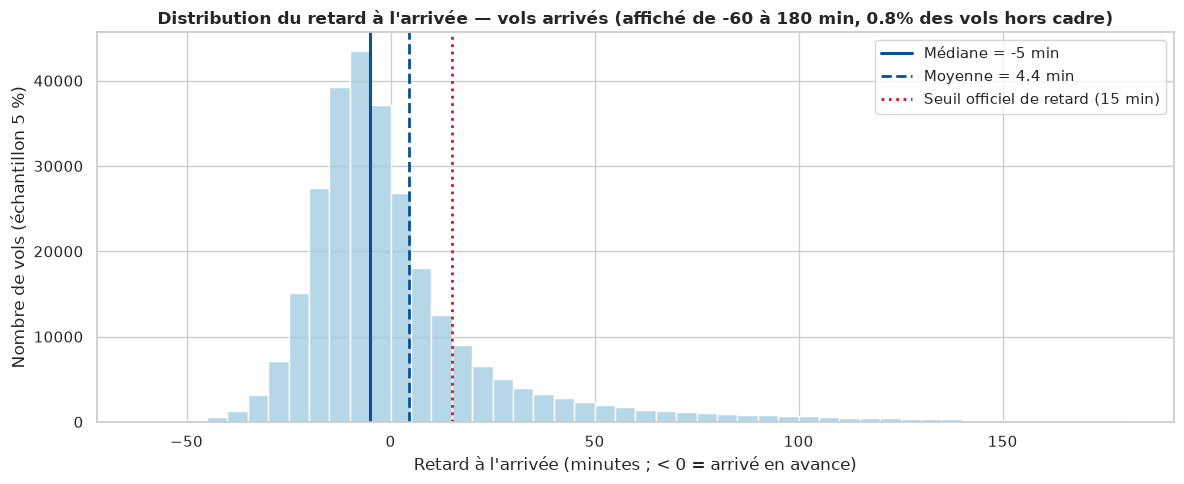

In [9]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
sns.set_theme(style="whitegrid", context="notebook")
SILVER_MAIN_PATH = globals().get("SILVER_MAIN_PATH", "/lakehouse/silver/flights_enriched")

silver_eda = spark.read.format("delta").load(SILVER_MAIN_PATH)

# Périmètre
perimetre = silver_eda.agg(
    F.count("*").alias("n_total"),
    F.sum(F.col("is_cancelled").cast("int")).alias("n_annules"),
    F.sum(F.col("is_diverted").cast("int")).alias("n_derouted"),
    F.sum(F.col("arrival_delay").isNotNull().cast("int")).alias("n_arrival_delay_renseigne"),
).first().asDict()
print("=== Périmètre ===")
for k, v in perimetre.items():
    print(f"  {k:<28} {v:>9,}  ({v / perimetre['n_total']:6.2%})")

# arrival_delay n'existe que pour les vols arrivés
flown_eda = silver_eda.filter(~F.col("is_cancelled") & ~F.col("is_diverted") & F.col("arrival_delay").isNotNull()).cache()

# Forme de la distribution de arrival_delay
probs = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
d = flown_eda.agg(
    F.count("arrival_delay").alias("n"),
    F.mean("arrival_delay").alias("moyenne"),
    F.stddev("arrival_delay").alias("ecart_type"),
    F.skewness("arrival_delay").alias("skewness"),
    F.min("arrival_delay").alias("min"),
    F.max("arrival_delay").alias("max"),
    F.percentile_approx("arrival_delay", probs, 10000).alias("q"),
    F.avg((F.col("arrival_delay") < 0).cast("int")).alias("part_en_avance"),
    F.avg((F.col("arrival_delay") >= 15).cast("int")).alias("taux_retard_15"),
    F.avg((F.col("arrival_delay") >= 60).cast("int")).alias("taux_retard_60"),
).first().asDict()
q = dict(zip(probs, d.pop("q")))

print("\n=== Distribution de arrival_delay (vols arrivés, minutes) ===")
print(f"  n = {d['n']:,} | min = {d['min']} | max = {d['max']}")
print(f"  Moyenne = {d['moyenne']:.2f} | Écart-type = {d['ecart_type']:.2f} | Skewness = {d['skewness']:.2f}")
print("  Quantiles : " + " | ".join(f"P{int(p*100)} = {v}" for p, v in q.items()))
print(f"  Médiane = {q[0.5]} | IQR (P75 - P25) = {q[0.75] - q[0.25]}")
print(f"  Vols en avance (< 0)      : {d['part_en_avance']:.1%}")
print(f"  Vols en retard >= 15 min  : {d['taux_retard_15']:.1%}")
print(f"  Vols en retard >= 60 min  : {d['taux_retard_60']:.1%}")

# Poids de la queue
minutes = flown_eda.filter(F.col("arrival_delay") > 0).agg(
    F.sum("arrival_delay").alias("total"),
    F.sum(F.when(F.col("arrival_delay") >= 60, F.col("arrival_delay"))).alias("ge60"),
    F.count("*").alias("n_pos"),
    F.sum((F.col("arrival_delay") >= 60).cast("int")).alias("n_ge60"),
).first()
print(f"\nRetards >= 60 min : {minutes['n_ge60'] / minutes['n_pos']:.1%} des vols arrivés en retard "
      f"mais {minutes['ge60'] / minutes['total']:.1%} du total des minutes de retard")

# Histogramme
LOW, HIGH = -60, 180
hist_pd = (
    flown_eda.filter(F.col("arrival_delay").between(LOW, HIGH))
    .select("arrival_delay").sample(fraction=0.05, seed=42).toPandas()
)
part_masquee = 1 - flown_eda.filter(F.col("arrival_delay").between(LOW, HIGH)).count() / d["n"]

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(hist_pd["arrival_delay"], binwidth=5, color="#9ecae1", edgecolor="white", ax=ax)
ax.axvline(q[0.5], color="#08519c", linewidth=2.2, label=f"Médiane = {q[0.5]} min")
ax.axvline(d["moyenne"], color="#08519c", linestyle="--", linewidth=2, label=f"Moyenne = {d['moyenne']:.1f} min")
ax.axvline(15, color="#cb181d", linestyle=":", linewidth=2, label="Seuil officiel de retard (15 min)")
ax.set_title(f"Distribution du retard à l'arrivée — vols arrivés (affiché de {LOW} à {HIGH} min, {part_masquee:.1%} des vols hors cadre)",
             fontweight="bold")
ax.set_xlabel("Retard à l'arrivée (minutes ; < 0 = arrivé en avance)")
ax.set_ylabel("Nombre de vols (échantillon 5 %)")
ax.legend()
plt.tight_layout()
plt.show()


**Interprétation**

1,8 % des vols sont annulés ou déroutés : ils n'ont pas de retard à l'arrivée et sont exclus de cette mesure.

La distribution est très asymétrique (skewness de 6,5). La moyenne est de +4,4 min alors que la médiane est de −5 min : la plupart des vols arrivent en avance (61 %), et quelques très gros retards tirent la moyenne vers le haut. Les retards de plus d'une heure ne font que 16 % des vols en retard mais 58 % des minutes de retard. L'écart-type (39 min) est lui aussi gonflé par rapport à l'IQR (21 min).

La moyenne n'est donc pas un bon indicateur ici. Pour la suite on retient :
- le taux de vols en retard de 15 min ou plus, indicateur principal (simple à lire et peu sensible aux valeurs extrêmes) ;
- la médiane et l'IQR pour comparer les distributions entre groupes.

Sur l'ensemble, 18,6 % des vols arrivent en retard : c'est la référence pour les étapes suivantes.

Avant de chercher quand et où les retards se produisent, on regarde d'où ils viennent (étape 1).

### Étape 1 : d'où vient le retard ?

Avant de chercher les facteurs, on veut savoir à quel moment le retard apparaît et pour quelle raison. Cela nous dira quels facteurs étudier ensuite.

Deux analyses :
- un tableau croisé départ en retard / arrivée en retard (deux variables binaires), complété par le partage des minutes de retard entre le départ et le trajet ;
- la part des minutes de retard par cause. On compte les minutes plutôt que le nombre de vols pour tenir compte de la gravité, et on utilise des barres triées parce qu'il y a seulement 5 catégories à comparer.

Effectifs :
arrivee          arrivé en retard  arrivé à l'heure
depart                                             
parti en retard            830738            219684
parti à l'heure            232701           4430885

% par ligne :
arrivee          arrivé en retard  arrivé à l'heure
depart                                             
parti en retard              79.1              20.9
parti à l'heure               5.0              95.0

Parmi les vols arrivés en retard, % partis à l'heure : 21.9



Vols en retard : 93.3% des minutes de retard existent déjà au départ, 6.7% s'ajoutent pendant le trajet (roulage + vol)



Répartition des minutes de retard par cause :
                                             cause  minutes  part_pct
                         Avion précédent en retard 24961931      39.8
   Compagnie (équipage, maintenance, embarquement) 20172956      32.2
Système aérien (trafic, contrôle aérien, aéroport) 14335762      22.9
                                     Météo extrême  3100233       4.9
                                          Sécurité    80985       0.1


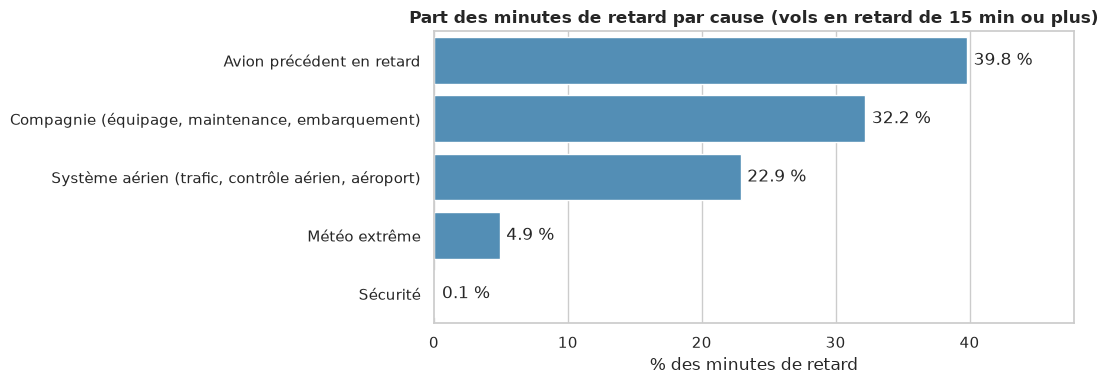

In [10]:
# Le retard se crée-t-il avant ou après le départ ?
dep_arr_pd = (
    flown_eda.filter(F.col("departure_delay").isNotNull())
    .withColumn("depart", F.when(F.col("departure_delay") >= 15, "parti en retard").otherwise("parti à l'heure"))
    .withColumn("arrivee", F.when(F.col("is_delayed_15"), "arrivé en retard").otherwise("arrivé à l'heure"))
    .groupBy("depart", "arrivee").count()
    .toPandas()
)
ct = pd.crosstab(dep_arr_pd["depart"], dep_arr_pd["arrivee"], values=dep_arr_pd["count"], aggfunc="sum")
print("Effectifs :")
print(ct.to_string())
print("\n% par ligne :")
print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1).to_string())
print("\nParmi les vols arrivés en retard, % partis à l'heure :",
      round(100 * ct.loc["parti à l'heure", "arrivé en retard"] / ct["arrivé en retard"].sum(), 1))

# Pour les vols en retard : minutes perdues au départ vs pendant le trajet
late = flown_eda.filter(F.col("is_delayed_15"))
split = late.agg(
    F.sum("departure_delay").alias("min_depart"),
    F.sum(F.col("arrival_delay") - F.col("departure_delay")).alias("min_trajet"),
).first()
total = split["min_depart"] + split["min_trajet"]
print(f"\nVols en retard : {split['min_depart'] / total:.1%} des minutes de retard existent déjà au départ, "
      f"{split['min_trajet'] / total:.1%} s'ajoutent pendant le trajet (roulage + vol)")

# Part des minutes de retard par cause
cause_labels = {
    "late_aircraft_delay": "Avion précédent en retard",
    "airline_delay": "Compagnie (équipage, maintenance, embarquement)",
    "air_system_delay": "Système aérien (trafic, contrôle aérien, aéroport)",
    "weather_delay": "Météo extrême",
    "security_delay": "Sécurité",
}
causes_pd = (
    late.agg(*[F.sum(c).alias(c) for c in cause_labels]).toPandas().T
    .rename(columns={0: "minutes"})
)
causes_pd["part_pct"] = (100 * causes_pd["minutes"] / causes_pd["minutes"].sum()).round(1)
causes_pd["cause"] = causes_pd.index.map(cause_labels)
causes_pd = causes_pd.sort_values("minutes", ascending=False)
print("\nRépartition des minutes de retard par cause :")
print(causes_pd[["cause", "minutes", "part_pct"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=causes_pd, x="part_pct", y="cause", color="#4292c6", ax=ax)
for i, v in enumerate(causes_pd["part_pct"]):
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center")
ax.set_title("Part des minutes de retard par cause (vols en retard de 15 min ou plus)", fontweight="bold")
ax.set_xlabel("% des minutes de retard")
ax.set_ylabel("")
ax.set_xlim(0, causes_pd["part_pct"].max() + 8)
plt.tight_layout()
plt.show()


**Interprétation**

Le retard se joue surtout avant le décollage : 79 % des vols partis en retard arrivent en retard (5 % pour les autres), et 93 % des minutes de retard existent déjà au départ.

Les causes orientent la suite :
- avion précédent en retard (40 %) : le retard se propage, à vérifier selon l'heure (étape 2) ;
- compagnie (32 %) : comparer les compagnies (étape 3) ;
- système aérien (23 %) : dépend de l'aéroport (étape 4) ;
- météo extrême (5 %) : la météo ordinaire est comptée dans le système aérien, effet saisonnier possible (étape 2).

### Étape 2 : quand les vols sont-ils en retard ?

L'étape 1 a montré que le retard se propage d'un vol à l'autre et que la météo peut jouer. On vérifie ces deux pistes avec le taux de retard par heure de départ prévue, par jour et par mois. Ces trois variables sont ordonnées, d'où des courbes, comparées au taux global de 18,6 %. Pour chaque groupe, on calcule aussi la part des minutes de retard due à l'avion précédent et, par mois, la part des annulations dues à la météo.

Par heure de départ prévue :
 dep_hour  n_vols  taux_retard  part_min_avion_precedent
        0   14504         15.9                      30.9
        1    5091         18.8                      32.1
        2    1383         17.1                      60.4
        3     767         17.7                      79.3
        4     526         20.2                      64.8
        5  115647          7.3                       3.7
        6  398508          9.0                       4.7
        7  387719         11.2                      10.2
        8  374828         12.9                      17.3
        9  346299         14.2                      28.6
       10  366008         15.4                      37.1
       11  352601         16.4                      39.2
       12  349867         17.6                      42.2
       13  357775         19.0                      42.2
       14  323785         20.9                      43.3
       15  361296         21.5                      43.5
  

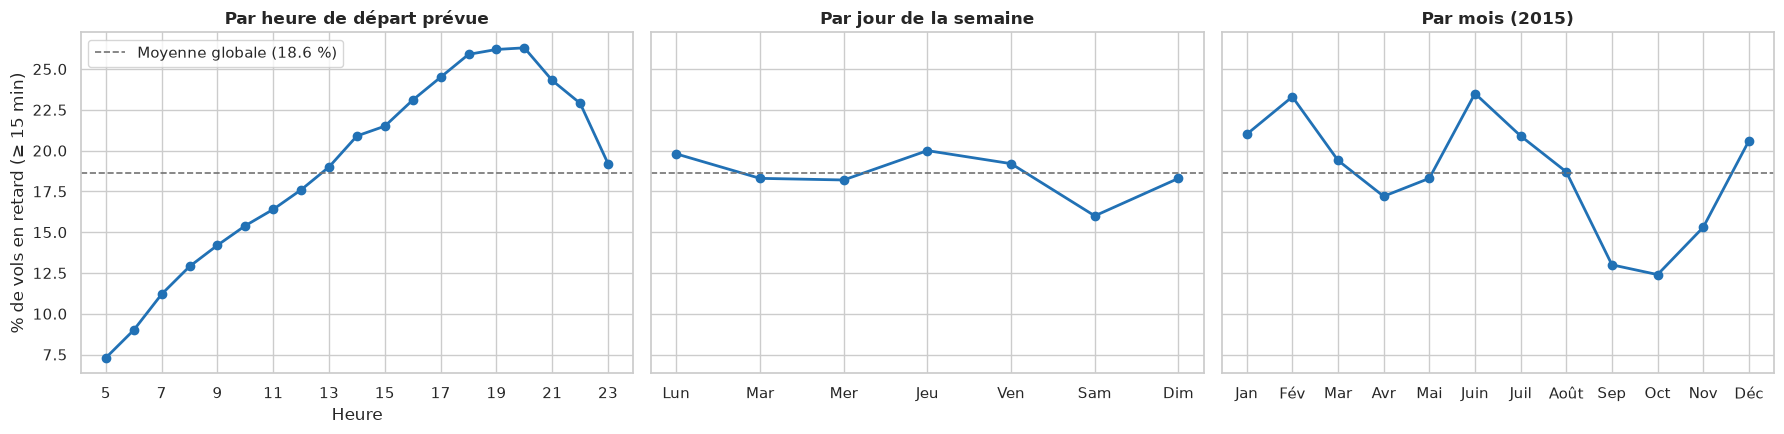

In [11]:
TAUX_REF = 100 * d["taux_retard_15"]  # taux global calculé à l'étape 0

def taux_par(col):
    return (
        flown_eda.groupBy(col)
        .agg(
            F.count("*").alias("n_vols"),
            F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1).alias("taux_retard"),
            F.round(100 * F.sum("late_aircraft_delay") / F.sum(F.when(F.col("is_delayed_15"), F.col("arrival_delay"))), 1)
             .alias("part_min_avion_precedent"),
        )
        .orderBy(col)
        .toPandas()
    )

heure_pd = taux_par("dep_hour")
jour_pd = taux_par("day_of_week")
mois_pd = taux_par("month")

# Annulations par mois, et part des annulations dues à la météo (motif B)
annul_pd = (
    silver_eda.groupBy("month")
    .agg(
        F.round(100 * F.avg(F.col("is_cancelled").cast("int")), 2).alias("taux_annulation"),
        F.round(100 * F.avg((F.col("cancellation_reason") == "B").cast("int")), 2).alias("part_annul_meteo"),
    )
    .orderBy("month").toPandas()
)
mois_pd = mois_pd.merge(annul_pd, on="month")

print("Par heure de départ prévue :")
print(heure_pd.to_string(index=False))
print("\nPar jour (1 = lundi) :")
print(jour_pd.to_string(index=False))
print("\nPar mois :")
print(mois_pd.to_string(index=False))

# Entre minuit et 5 h il y a très peu de vols : on trace de 5 h à 23 h
heure_plot = heure_pd[heure_pd["dep_hour"] >= 5]
jours = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
mois_lbl = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
axes[0].plot(heure_plot["dep_hour"], heure_plot["taux_retard"], marker="o", color="#2171b5", linewidth=2)
axes[0].set_xticks(range(5, 24, 2))
axes[0].set_title("Par heure de départ prévue", fontweight="bold")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("% de vols en retard (≥ 15 min)")

axes[1].plot(jours, jour_pd["taux_retard"], marker="o", color="#2171b5", linewidth=2)
axes[1].set_title("Par jour de la semaine", fontweight="bold")

axes[2].plot(mois_lbl, mois_pd["taux_retard"], marker="o", color="#2171b5", linewidth=2)
axes[2].set_title("Par mois (2015)", fontweight="bold")

for ax in axes:
    ax.axhline(TAUX_REF, color="#737373", linestyle="--", linewidth=1.2, label=f"Moyenne globale ({TAUX_REF:.1f} %)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()


**Interprétation**

- Heure : le taux de retard passe de 7 % à 5 h à 26 % vers 19-20 h, et la part due à l'avion précédent de 4 % à 51 %. Cela confirme la propagation au fil de la journée. C'est le facteur temporel le plus fort.
- Mois : pics en février (23 %, 75 % des annulations dues à la météo), en juin (23 %) et en décembre, creux en septembre-octobre (12 à 13 %). La saison joue, en partie via la météo.
- Jour : peu d'écart (16 % le samedi, 18 à 20 % les autres jours). Facteur secondaire.

On retient l'heure et le mois pour la suite (hypothèses à tester en J4, table Gold mensuelle en J3).

### Étape 2 bis : quel est le poids des événements exceptionnels ?

Les pics de février, juin et décembre pourraient venir de quelques journées exceptionnelles (tempêtes, pannes) plutôt que de la saison. On calcule les taux jour par jour et on repère les jours exceptionnels avec la règle de Tukey (au-dessus de Q3 + 1,5 IQR), en retard ou en annulation. On compare ensuite les taux mensuels avec et sans ces jours. Les dates des plus gros pics ont été recoupées avec les rapports de la NOAA et la presse.

Seuils : retard > 38.4 % ou annulation > 3.3 %  ->  46 jours exceptionnels sur 365

Les 8 jours avec le plus d'annulations :
flight_date  n_vols  taux_retard  taux_annulation
 2015-01-27   15155          7.1             19.0
 2015-02-02   15975         28.9             17.5
 2015-03-05   16622         31.2             17.2
 2015-02-01   13406         21.8             14.8
 2015-12-28   16312         36.4             13.3
 2015-01-26   15890         18.1             10.1
 2015-03-01   15171         41.3             10.0
 2015-02-15   14408         22.4              9.5

Taux mensuels (%) avec et sans les jours exceptionnels :
       jours_exceptionnels  retard_tous  retard_sans  annulation_tous  annulation_sans
month                                                                                 
1                        7        21.00        19.56             2.55             1.30
2                       16        23.35        18.98             4.78             1.23
3                  

/tmp/ipykernel_59229/3046025876.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(jour_pd.nlargest(8, "taux_annulation")[["flight_date", "n_vols", "taux_retard", "taux_annulation"]].round(1).to_string(index=False))


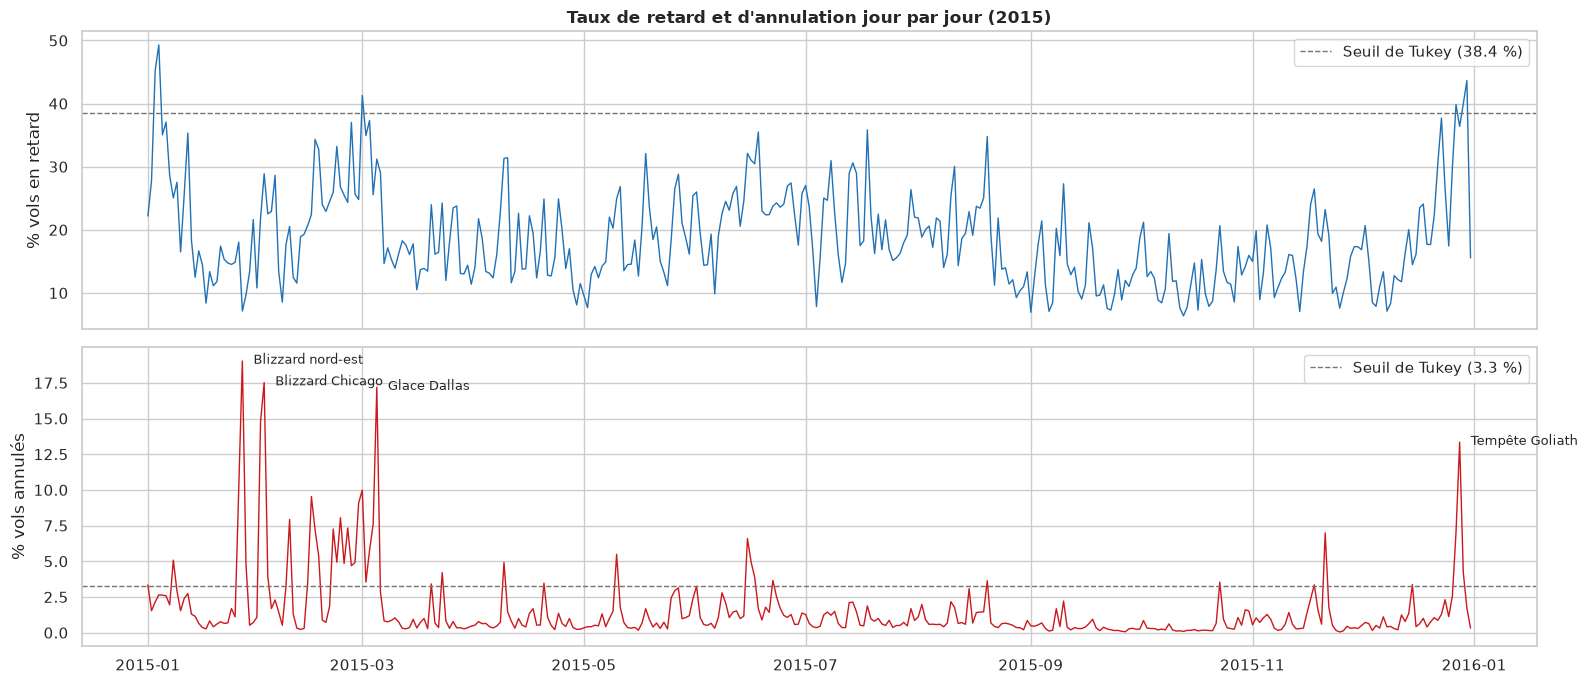

In [12]:
# Taux de retard et d'annulation pour chaque jour de 2015
jour_pd = (
    silver_eda.groupBy("flight_date")
    .agg(
        F.count("*").alias("n_vols"),
        F.count("is_delayed_15").alias("n_arrives"),  # le retard ne porte que sur les vols arrivés
        (100 * F.avg(F.col("is_delayed_15").cast("int"))).alias("taux_retard"),
        (100 * F.avg(F.col("is_cancelled").cast("int"))).alias("taux_annulation"),
    )
    .orderBy("flight_date").toPandas()
)
jour_pd["flight_date"] = pd.to_datetime(jour_pd["flight_date"])
jour_pd["month"] = jour_pd["flight_date"].dt.month

# Jour exceptionnel = au-dessus du seuil de Tukey (Q3 + 1,5 IQR) en retard ou en annulation
def seuil_tukey(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

seuil_ret, seuil_ann = seuil_tukey(jour_pd["taux_retard"]), seuil_tukey(jour_pd["taux_annulation"])
jour_pd["exceptionnel"] = (jour_pd["taux_retard"] > seuil_ret) | (jour_pd["taux_annulation"] > seuil_ann)
print(f"Seuils : retard > {seuil_ret:.1f} % ou annulation > {seuil_ann:.1f} %  ->  {jour_pd['exceptionnel'].sum()} jours exceptionnels sur {len(jour_pd)}")
print("\nLes 8 jours avec le plus d'annulations :")
print(jour_pd.nlargest(8, "taux_annulation")[["flight_date", "n_vols", "taux_retard", "taux_annulation"]].round(1).to_string(index=False))

# Taux mensuels avec / sans jours exceptionnels
def taux_pondere(x, col):
    poids = x["n_arrives"] if col == "taux_retard" else x["n_vols"]
    return round((x[col] * poids).sum() / poids.sum(), 2)

comp = pd.DataFrame({
    "jours_exceptionnels": jour_pd.groupby("month")["exceptionnel"].sum(),
    "retard_tous": jour_pd.groupby("month").apply(taux_pondere, "taux_retard"),
    "retard_sans": jour_pd[~jour_pd["exceptionnel"]].groupby("month").apply(taux_pondere, "taux_retard"),
    "annulation_tous": jour_pd.groupby("month").apply(taux_pondere, "taux_annulation"),
    "annulation_sans": jour_pd[~jour_pd["exceptionnel"]].groupby("month").apply(taux_pondere, "taux_annulation"),
})
print("\nTaux mensuels (%) avec et sans les jours exceptionnels :")
print(comp.to_string())

# Événements identifiés (sources : NOAA, presse locale)
evenements = {
    "2015-01-27": "Blizzard nord-est",
    "2015-02-02": "Blizzard Chicago",
    "2015-03-05": "Glace Dallas",
    "2015-12-28": "Tempête Goliath",
}

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
axes[0].plot(jour_pd["flight_date"], jour_pd["taux_retard"], color="#2171b5", linewidth=1)
axes[0].axhline(seuil_ret, color="#737373", linestyle="--", linewidth=1, label=f"Seuil de Tukey ({seuil_ret:.1f} %)")
axes[0].set_ylabel("% vols en retard")
axes[0].set_title("Taux de retard et d'annulation jour par jour (2015)", fontweight="bold")
axes[0].legend(loc="upper right")

axes[1].plot(jour_pd["flight_date"], jour_pd["taux_annulation"], color="#cb181d", linewidth=1)
axes[1].axhline(seuil_ann, color="#737373", linestyle="--", linewidth=1, label=f"Seuil de Tukey ({seuil_ann:.1f} %)")
for date, label in evenements.items():
    y = jour_pd.loc[jour_pd["flight_date"] == date, "taux_annulation"].iloc[0]
    axes[1].annotate(label, (pd.Timestamp(date), y), xytext=(8, -2), textcoords="offset points", fontsize=9)
axes[1].set_ylabel("% vols annulés")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()


**Interprétation**

- 46 jours sur 365 sont exceptionnels. Les plus gros pics d'annulations correspondent à des tempêtes : blizzard du nord-est le 27 janvier (19 % d'annulations, New York), blizzard de Chicago le 1er-2 février, tempête de glace à Dallas le 5 mars, tempête Goliath les 27-28 décembre (Chicago et Dallas). Les pics de retard sans annulation correspondent aux retours de vacances (3-4 janvier, 29-30 décembre).
- Les annulations viennent presque entièrement de ces événements : sans eux, février passe de 4,8 % à 1,2 %.
- Pour les retards, c'est plus nuancé. Le pic de février vient surtout des tempêtes : sans ces jours, il retombe à 19,0 %, à peine au-dessus de la moyenne (18,6 %). En revanche, juin reste haut (22,6 %) et septembre-octobre restent bas (13 % et 12 %).

Le mois reste donc un facteur de retard, mais surtout par l'opposition été / automne ; l'hiver joue surtout par ses tempêtes. Ces événements ne sont pas prévisibles à la réservation ; on les garde dans les données, mais ils expliquent la plupart des annulations.

### Étape 3 : les compagnies se valent-elles ?

32 % des minutes de retard sont imputées aux compagnies elles-mêmes (étape 1). On compare donc les 14 compagnies sur le taux de retard (barres triées), avec la médiane et l'IQR en complément. Comme l'heure joue beaucoup (étape 2), on vérifie que les écarts ne viennent pas seulement des horaires : part des vols après 14 h, et taux de retard avant et après 14 h.

airline                 airline_name  n_vols  taux_retard  mediane  iqr  taux_annulation  part_min_compagnie  part_vols_apres_14h
     HA       Hawaiian Airlines Inc.   76272         11.3       -2   11             0.22                57.6                 43.8
     AS         Alaska Airlines Inc.  172521         13.0       -5   18             0.39                32.3                 46.2
     DL         Delta Air Lines Inc.  875881         13.6       -8   18             0.44                37.4                 46.1
     AA       American Airlines Inc.  725984         18.3       -6   22             1.50                35.2                 45.2
     OO        Skywest Airlines Inc.  588353         18.7       -4   20             1.69                31.4                 46.2
     US              US Airways Inc.  198715         18.8       -4   21             2.05                34.6                 46.3
     WN       Southwest Airlines Co. 1261855         19.0       -4   20             1.27  


Taux de retard par créneau :
         avant 14h  après 14h
airline                      
HA             9.7       13.5
AS            11.4       15.0
DL            10.2       17.5
AA            14.3       23.1
OO            16.3       21.5
US            14.9       23.3
WN            11.6       27.6
VX            16.1       22.7
EV            15.9       24.2
UA            16.4       25.8
MQ            19.0       24.9
B6            15.3       30.3
F9            20.8       30.8
NK            24.7       34.8


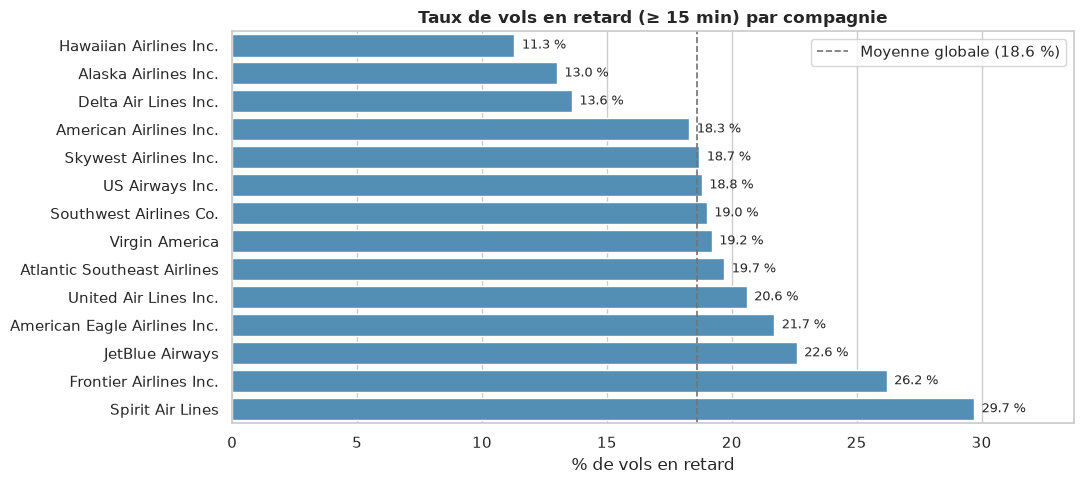

In [13]:
cie_pd = (
    silver_eda.groupBy("airline", "airline_name")
    .agg(
        F.count("*").alias("n_vols"),
        F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1).alias("taux_retard"),
        F.percentile_approx("arrival_delay", 0.5).alias("mediane"),
        (F.percentile_approx("arrival_delay", 0.75) - F.percentile_approx("arrival_delay", 0.25)).alias("iqr"),
        F.round(100 * F.avg(F.col("is_cancelled").cast("int")), 2).alias("taux_annulation"),
        # part des minutes de retard imputées à la compagnie elle-même
        F.round(100 * F.sum("airline_delay") / F.sum(F.when(F.col("is_delayed_15"), F.col("arrival_delay"))), 1).alias("part_min_compagnie"),
        # part des vols programmés l'après-midi / le soir (heures où le retard est plus fréquent)
        F.round(100 * F.avg((F.col("dep_hour") >= 14).cast("int")), 1).alias("part_vols_apres_14h"),
    )
    .orderBy("taux_retard")
    .toPandas()
)
print(cie_pd.to_string(index=False))

# Compagnies à heure égale
cie_creneau_pd = (
    flown_eda
    .withColumn("creneau", F.when(F.col("dep_hour") < 14, "avant 14h").otherwise("après 14h"))
    .groupBy("airline").pivot("creneau", ["avant 14h", "après 14h"])
    .agg(F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1))
    .toPandas().set_index("airline").loc[cie_pd["airline"]]
)
print("\nTaux de retard par créneau :")
print(cie_creneau_pd.to_string())

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=cie_pd, x="taux_retard", y="airline_name", color="#4292c6", ax=ax)
ax.axvline(TAUX_REF, color="#737373", linestyle="--", linewidth=1.2, label=f"Moyenne globale ({TAUX_REF:.1f} %)")
for i, v in enumerate(cie_pd["taux_retard"]):
    ax.text(v + 0.3, i, f"{v:.1f} %", va="center", fontsize=9)
ax.set_title("Taux de vols en retard (≥ 15 min) par compagnie", fontweight="bold")
ax.set_xlabel("% de vols en retard")
ax.set_ylabel("")
ax.set_xlim(0, cie_pd["taux_retard"].max() + 4)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


**Interprétation**

- L'écart est important : de 11,3 % (Hawaiian) à 29,7 % (Spirit). Delta et Alaska sont aussi sous les 14 %, Frontier et JetBlue au-dessus de 22 %.
- Ce n'est pas une question d'horaires : toutes les compagnies ont 44 à 53 % de vols après 14 h, et le classement reste le même à créneau égal (le matin, 10 % pour Delta contre 25 % pour Spirit).
- La compagnie est donc un facteur à part entière. American Eagle se distingue par ses annulations (5,1 %).

On retient la compagnie pour la suite (test de Kruskal-Wallis en J4, classement en table Gold en J3).

### Étape 4 : les aéroports ont-ils des profils différents ?

23 % des minutes de retard viennent du système aérien (trafic, contrôle, capacité), donc en partie de l'aéroport (étape 1). On calcule pour chaque aéroport de départ le taux de retard, le taux d'annulation, le temps de roulage médian (signe de congestion) et la part due au système aérien. On garde les aéroports avec au moins 1 000 vols dans l'année (environ 3 par jour) : le taux de retard est alors connu à ±2,5 points près, et on écarte les très petits aéroports isolés (Alaska), et octobre est exclu (codes non valides). Nos données ont les coordonnées GPS : une carte montre directement si la géographie joue. Le lien entre indicateurs est mesuré avec Spearman, plus robuste sur 225 points.

225 aéroports avec au moins 1 000 vols (99% des vols)

Les 8 moins touchés :
origin_airport origin_city  n_vols  taux_retard  taux_annulation  taxi_out_median  part_min_systeme
           ITO        Hilo    5723          8.5             0.21                8               2.5
           GTF Great Falls    1966          9.3             0.71               12              28.8
           HLN      Helena    1435          9.6             0.63               12              44.2
           LIH       Lihue   10545          9.7             0.42                7               7.2
           BIL    Billings    2866         10.3             0.45               11              21.5
           KOA Kailua/Kona   11114         10.5             0.36                9               6.9
           IDA Idaho Falls    2247         10.7             0.85               11              22.5
           HNL    Honolulu   43172         10.8             0.40               14               7.8

Les 8 plus touchés :
o

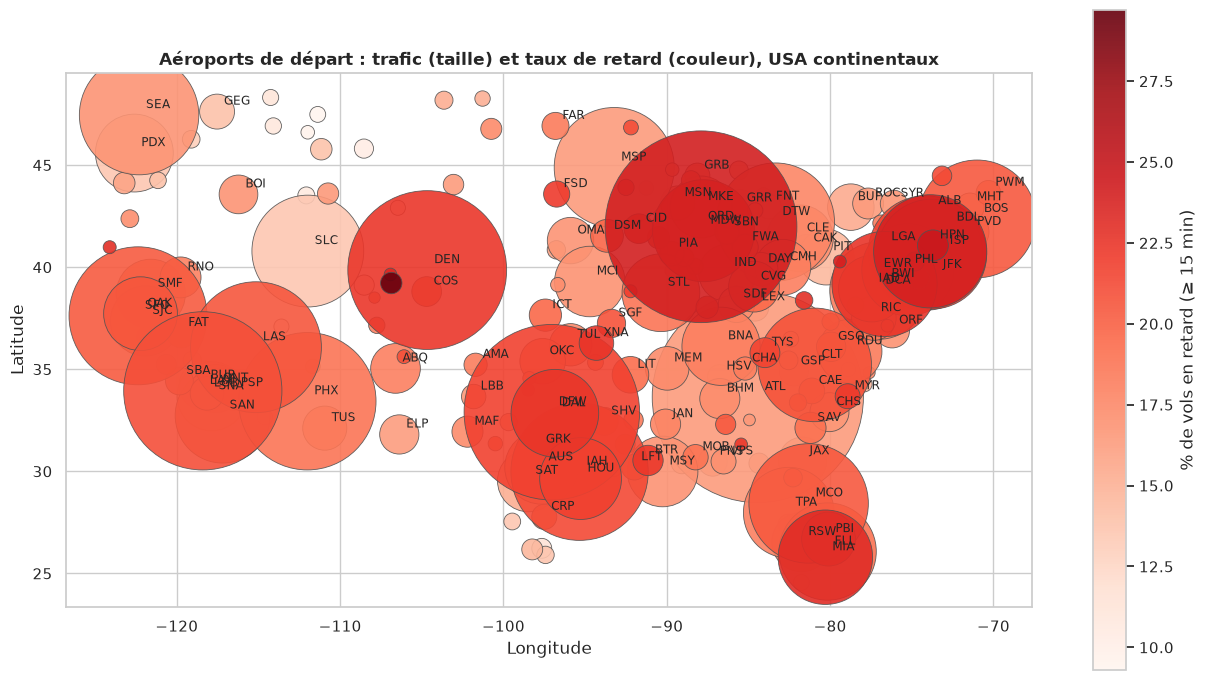

In [14]:
# Profil des aéroports de départ (octobre exclu : codes aéroport non valides)
apt_pd = (
    silver_eda.filter(F.col("airport_code_valid"))
    .groupBy("origin_airport", "origin_city", "origin_state", "origin_lat", "origin_lon")
    .agg(
        F.count("*").alias("n_vols"),
        F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1).alias("taux_retard"),
        F.round(100 * F.avg(F.col("is_cancelled").cast("int")), 2).alias("taux_annulation"),
        F.percentile_approx("taxi_out", 0.5).alias("taxi_out_median"),
        F.round(100 * F.sum("air_system_delay") / F.sum(F.when(F.col("is_delayed_15"), F.col("arrival_delay"))), 1).alias("part_min_systeme"),
    )
    .toPandas()
)
apt_pd = apt_pd[apt_pd["n_vols"] >= 1000].sort_values("taux_retard")
print(f"{len(apt_pd)} aéroports avec au moins 1 000 vols "
      f"({apt_pd['n_vols'].sum() / silver_eda.filter('airport_code_valid').count():.0%} des vols)")
cols = ["origin_airport", "origin_city", "n_vols", "taux_retard", "taux_annulation", "taxi_out_median", "part_min_systeme"]
print("\nLes 8 moins touchés :")
print(apt_pd[cols].head(8).to_string(index=False))
print("\nLes 8 plus touchés :")
print(apt_pd[cols].tail(8).to_string(index=False))

# Le roulage au départ (signe de congestion) va-t-il avec le retard ?
print("\nCorrélation de Spearman entre aéroports :")
print(apt_pd[["taux_retard", "taxi_out_median", "taux_annulation", "part_min_systeme", "n_vols"]]
      .corr(method="spearman")["taux_retard"].round(2).to_string())

# Carte : position = coordonnées GPS, taille = trafic, couleur = taux de retard
carte = apt_pd[(apt_pd["origin_lon"] > -130) & (apt_pd["origin_lat"] > 23)]  # USA continentaux
fig, ax = plt.subplots(figsize=(13, 7))
sc = ax.scatter(carte["origin_lon"], carte["origin_lat"], s=carte["n_vols"] / 15, c=carte["taux_retard"],
                cmap="Reds", edgecolors="#525252", linewidth=0.6, alpha=0.9)
decalages = {"LGA": (-28, 8), "JFK": (8, -10), "EWR": (-30, -10)}  # aéroports de New York, très proches
for _, r in carte[carte["n_vols"] >= 4000].iterrows():
    ax.annotate(r["origin_airport"], (r["origin_lon"], r["origin_lat"]), xytext=decalages.get(r["origin_airport"], (5, 5)),
                textcoords="offset points", fontsize=8.5)
plt.colorbar(sc, ax=ax, label="% de vols en retard (≥ 15 min)")
ax.set_title("Aéroports de départ : trafic (taille) et taux de retard (couleur), USA continentaux", fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1.25)
plt.tight_layout()
plt.show()


**Interprétation**

- Les aéroports varient de 8,5 % (Hilo) à 30 % (Aspen). Les moins touchés sont à Hawaï, dans le nord des Rocheuses (Great Falls, Helena, Billings, Idaho Falls) et dans le nord-ouest (Portland et Salt Lake City, 13,6 %). Les plus touchés sont dans le nord-est (New York, White Plains, Trenton), à Chicago, Miami et dans les stations de ski du Colorado (Aspen, Eagle).
- Les annulations vont le plus avec le retard (ρ = 0,36), puis le roulage (ρ = 0,21) : la congestion joue, mais moins qu'on pouvait le penser. La taille compte peu (ρ = 0,19). Atlanta, le plus gros aéroport, reste sous la moyenne (16,4 %).
- Les aéroports combinent ces indicateurs de façon différente (LGA : congestion et annulations ; DAL : roulage court mais beaucoup de retards, 22,5 %). Une segmentation K-Means des aéroports en J4 a donc du sens, avec ces indicateurs comme variables.

### Étape 5 : vue d'ensemble des aéroports par ACP

L'étape 4 a montré que les aéroports combinent plusieurs indicateurs de façon différente. Pour les regarder tous en même temps, on fait une Analyse en Composantes Principales (ACP) sur les aéroports de départ (au moins 1 000 vols, octobre exclu).

Variables, toutes calculées par aéroport :
- résultat : taux de retard (≥ 15 min), taux d'annulation ;
- congestion : roulage au départ médian, trafic (en log, car très asymétrique) ;
- type de desserte : distance médiane, part des départs après 17 h ;
- origine des minutes de retard : part due au système aérien, à la météo, à un avion arrivé en retard.

Les variables n'ont pas les mêmes unités, on les centre-réduit (`StandardScaler`) avant l'ACP. On lit le cercle des corrélations (ce que représente chaque axe) et la projection des aéroports. Ces mêmes variables serviront au K-Means en J4.


225 aéroports, 9 variables centrées-réduites
Variance expliquée : CP1 = 26.9% | CP2 = 22.3% | CP3 = 12.9% | CP4 = 11.9% | CP5 = 8.9%
Cumul CP1 + CP2 = 49.2% | CP1 à CP3 = 62.1%

Corrélation de chaque variable avec les 3 premiers axes :
                     CP1   CP2   CP3
taux_retard         0.34 -0.50  0.60
taux_annulation    -0.42 -0.63  0.50
roulage_median      0.65 -0.38 -0.17
log_trafic          0.84  0.09  0.17
distance_mediane    0.69  0.14  0.11
part_depart_soir    0.62  0.29  0.22
part_systeme        0.16 -0.67 -0.41
part_meteo         -0.20 -0.40  0.29
part_avion_retarde -0.25  0.70  0.43


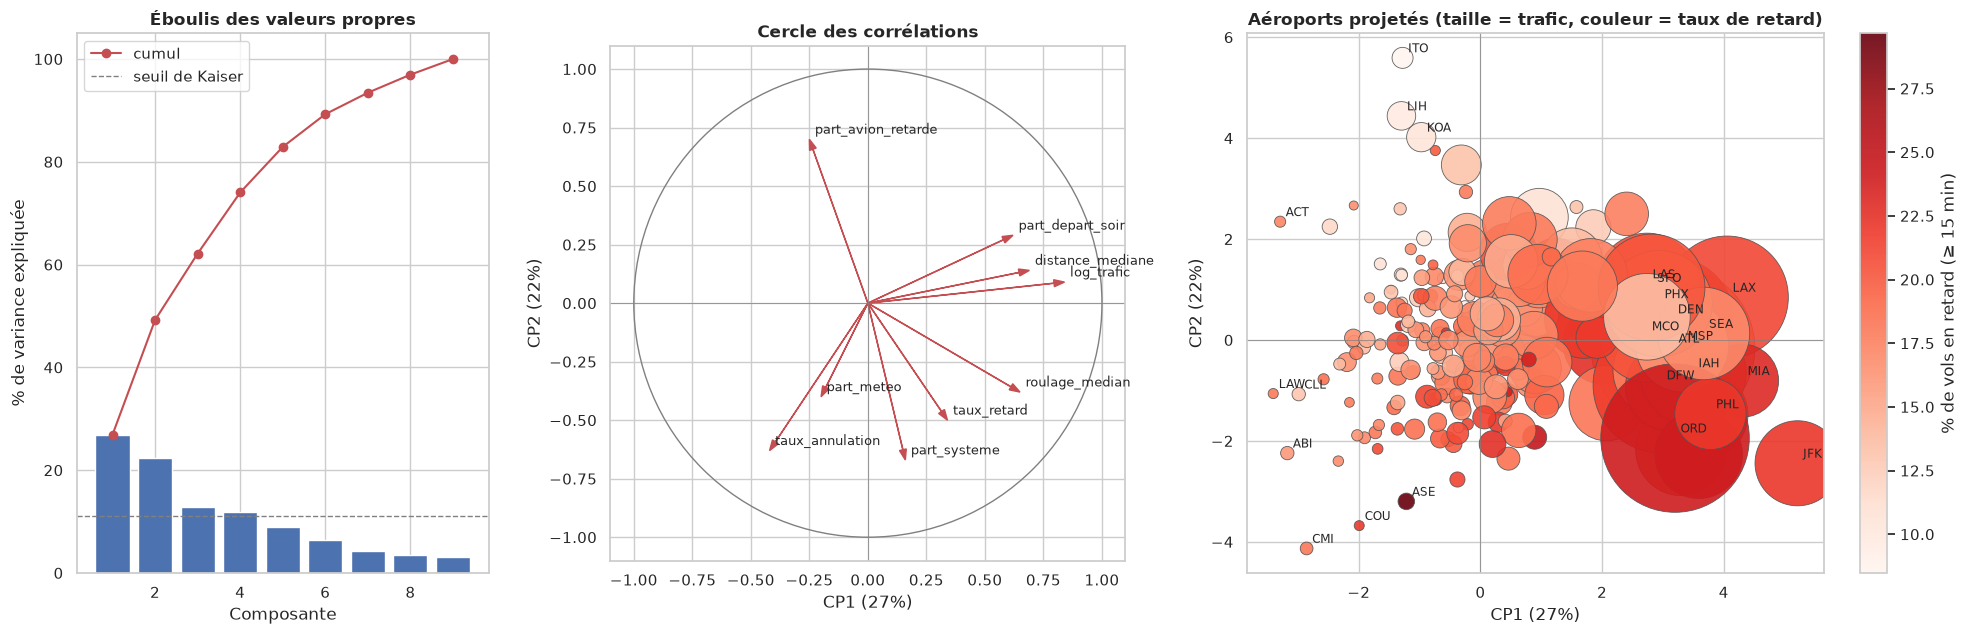


CP1 - les 5 plus négatifs :
origin_airport      origin_city  n_vols  taux_retard  roulage_median  distance_mediane  part_meteo   CP1
           LAW           Lawton    1331        17.96               8               140       11.35 -3.41
           ACT             Waco    1612        17.30               8                89        0.55 -3.29
           ABI          Abilene    2329        16.05               8               158       19.34 -3.17
           CLL  College Station    2311        13.00               8               164        9.05 -2.99
           CMI Champaign/Urbana    2116        18.10              10               135       20.35 -2.86
CP1 - les 5 plus positifs :
origin_airport  origin_city  n_vols  taux_retard  roulage_median  distance_mediane  part_meteo  CP1
           JFK     New York   93811        22.10              24              1089        7.24 5.21
           MIA        Miami   69341        23.11              17              1085        5.83 4.30
           LA

In [15]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Une ligne par aéroport (agrégé dans Spark)
causes = ["air_system_delay", "weather_delay", "late_aircraft_delay", "airline_delay", "security_delay"]
total_causes = sum(F.coalesce(F.sum(c), F.lit(0)) for c in causes)
apt_acp = (
    silver_eda.filter(F.col("airport_code_valid"))
    .groupBy("origin_airport", "origin_city")
    .agg(
        F.count("*").alias("n_vols"),
        (100 * F.avg(F.col("is_delayed_15").cast("int"))).alias("taux_retard"),
        (100 * F.avg(F.col("is_cancelled").cast("int"))).alias("taux_annulation"),
        F.percentile_approx("taxi_out", 0.5).alias("roulage_median"),
        F.percentile_approx("distance", 0.5).alias("distance_mediane"),
        (100 * F.avg((F.col("dep_hour") >= 17).cast("int"))).alias("part_depart_soir"),
        (100 * F.sum("air_system_delay") / total_causes).alias("part_systeme"),
        (100 * F.sum("weather_delay") / total_causes).alias("part_meteo"),
        (100 * F.sum("late_aircraft_delay") / total_causes).alias("part_avion_retarde"),
    )
    .filter(F.col("n_vols") >= 1000)
    .toPandas()
    .dropna()
)
apt_acp["log_trafic"] = np.log10(apt_acp["n_vols"])

features = ["taux_retard", "taux_annulation", "roulage_median", "log_trafic", "distance_mediane",
            "part_depart_soir", "part_systeme", "part_meteo", "part_avion_retarde"]
X = StandardScaler().fit_transform(apt_acp[features])

# ACP
acp = PCA().fit(X)
var = acp.explained_variance_ratio_
coords = acp.transform(X)
apt_acp["CP1"], apt_acp["CP2"] = coords[:, 0], coords[:, 1]
print(f"{len(apt_acp)} aéroports, {len(features)} variables centrées-réduites")
print("Variance expliquée : " + " | ".join(f"CP{i+1} = {v:.1%}" for i, v in enumerate(var[:5])))
print(f"Cumul CP1 + CP2 = {var[:2].sum():.1%} | CP1 à CP3 = {var[:3].sum():.1%}")

# Corrélations variables / axes
correl = pd.DataFrame(acp.components_[:3].T * np.sqrt(acp.explained_variance_[:3]),
                      index=features, columns=["CP1", "CP2", "CP3"]).round(2)
print("\nCorrélation de chaque variable avec les 3 premiers axes :")
print(correl.to_string())

# Éboulis, cercle des corrélations, projection
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), gridspec_kw={"width_ratios": [0.8, 1, 1.4]})

ax = axes[0]
ax.bar(range(1, len(var) + 1), 100 * var, color="#4C72B0")
ax.plot(range(1, len(var) + 1), 100 * np.cumsum(var), "o-", color="#C44E52", label="cumul")
ax.axhline(100 / len(features), ls="--", color="grey", lw=1, label="seuil de Kaiser")
ax.set_xlabel("Composante")
ax.set_ylabel("% de variance expliquée")
ax.set_title("Éboulis des valeurs propres", fontweight="bold")
ax.legend()

ax = axes[1]
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for f, (x, y) in correl[["CP1", "CP2"]].iterrows():
    ax.arrow(0, 0, x, y, head_width=0.03, color="#C44E52", length_includes_head=True)
    ax.annotate(f, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal",
       xlabel=f"CP1 ({var[0]:.0%})", ylabel=f"CP2 ({var[1]:.0%})")
ax.set_title("Cercle des corrélations", fontweight="bold")

ax = axes[2]
sc = ax.scatter(apt_acp["CP1"], apt_acp["CP2"], c=apt_acp["taux_retard"], s=apt_acp["n_vols"] / 25,
                cmap="Reds", edgecolors="#525252", linewidth=0.6, alpha=0.9)
a_nommer = pd.concat([apt_acp.nlargest(12, "n_vols"), apt_acp.nlargest(4, "CP1"), apt_acp.nsmallest(4, "CP1"),
                      apt_acp.nlargest(3, "CP2"), apt_acp.nsmallest(3, "CP2")]).drop_duplicates("origin_airport")
for _, r in a_nommer.iterrows():
    ax.annotate(r["origin_airport"], (r["CP1"], r["CP2"]), xytext=(4, 4), textcoords="offset points", fontsize=8.5)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
plt.colorbar(sc, ax=ax, label="% de vols en retard (≥ 15 min)")
ax.set(xlabel=f"CP1 ({var[0]:.0%})", ylabel=f"CP2 ({var[1]:.0%})")
ax.set_title("Aéroports projetés (taille = trafic, couleur = taux de retard)", fontweight="bold")
plt.tight_layout()
plt.show()

# Aéroports extrêmes sur chaque axe
cols = ["origin_airport", "origin_city", "n_vols", "taux_retard", "roulage_median", "distance_mediane", "part_meteo"]
for axe in ["CP1", "CP2"]:
    print(f"\n{axe} - les 5 plus négatifs :")
    print(apt_acp.nsmallest(5, axe)[cols + [axe]].round(2).to_string(index=False))
    print(f"{axe} - les 5 plus positifs :")
    print(apt_acp.nlargest(5, axe)[cols + [axe]].round(2).to_string(index=False))


**Interprétation**

- Pas de facteur unique : les deux premiers axes résument 49 % de l'information (27 % + 22 %) et 4 axes passent le seuil de Kaiser (11 %). On lit les trois premiers.
- **CP1 = taille du réseau.** Il est porté par le trafic (0,84), la distance (0,69), le roulage (0,65) et les départs du soir (0,62). À droite, les grands hubs (JFK, MIA, LAX, PHL, CLT) ; à gauche, les petits aéroports régionaux à vols courts (Lawton, Waco, Abilene au Texas). Le taux de retard n'y est que faiblement lié (0,34) : la taille seule ne fait pas le retard.
- **CP2 = deux façons d'être en retard.** En haut, le retard propagé (avion arrivé en retard, 0,70) : Hawaï (Hilo, Lihue, Kona, Kahului), où les rotations s'enchaînent mais où il y a peu de retards. En bas, le système aérien (−0,67), les annulations (−0,63), le taux de retard (−0,50) et la météo (−0,40) : des aéroports perturbés par le trafic et les événements (Champaign, Columbia, Aspen, Burlington, et JFK).
- **CP3 (13 %) = le niveau de retard et d'annulations** (0,60 et 0,50), en partie dû aux retards propagés (0,43) et à la météo (0,29), opposé au système aérien (−0,41).
- Le taux de retard est donc réparti sur plusieurs axes : un aéroport peut être en retard parce qu'il est un hub congestionné, parce qu'il subit le système aérien et la météo, ou parce que ses retards s'enchaînent. Classer les aéroports par taux de retard ne suffit pas, d'où la segmentation K-Means en J4 sur ces 9 variables.

### Conclusion de l'EDA

Indicateur retenu : le taux de vols en retard de 15 min ou plus (18,6 % en moyenne), avec la médiane et l'IQR en complément.

Facteurs connus à la réservation, du plus fort au plus faible :
1. l'heure de départ : de 7 % à 5 h à 26 % vers 19-20 h, à cause de la propagation des retards entre vols ;
2. la compagnie : de 11 % à 30 %, même à heure égale ;
3. le mois : de 12 % en octobre à 23 % en février et en juin ; sans les jours de tempête, juin reste haut mais février revient près de la moyenne (les annulations, elles, viennent surtout de ces événements) ;
4. l'aéroport de départ : de 8,5 % à 30 %, lié aux annulations et à la congestion ;
5. le jour de la semaine : effet faible.

Suite du projet :
- J3, tables Gold : classement des compagnies, évolution mensuelle, profil des aéroports.
- J4, tests : Kruskal-Wallis sur le retard entre compagnies, χ² entre créneau horaire et retard.
- J4, segmentation : K-Means sur les aéroports avec les 9 variables de l'ACP (étape 5), qui montre plusieurs façons d'être en retard : hubs congestionnés, aéroports perturbés par le système aérien et la météo, retards qui s'enchaînent.
- Dashboard : un voyageur choisit compagnie, aéroport, mois et créneau, et voit le risque de retard.